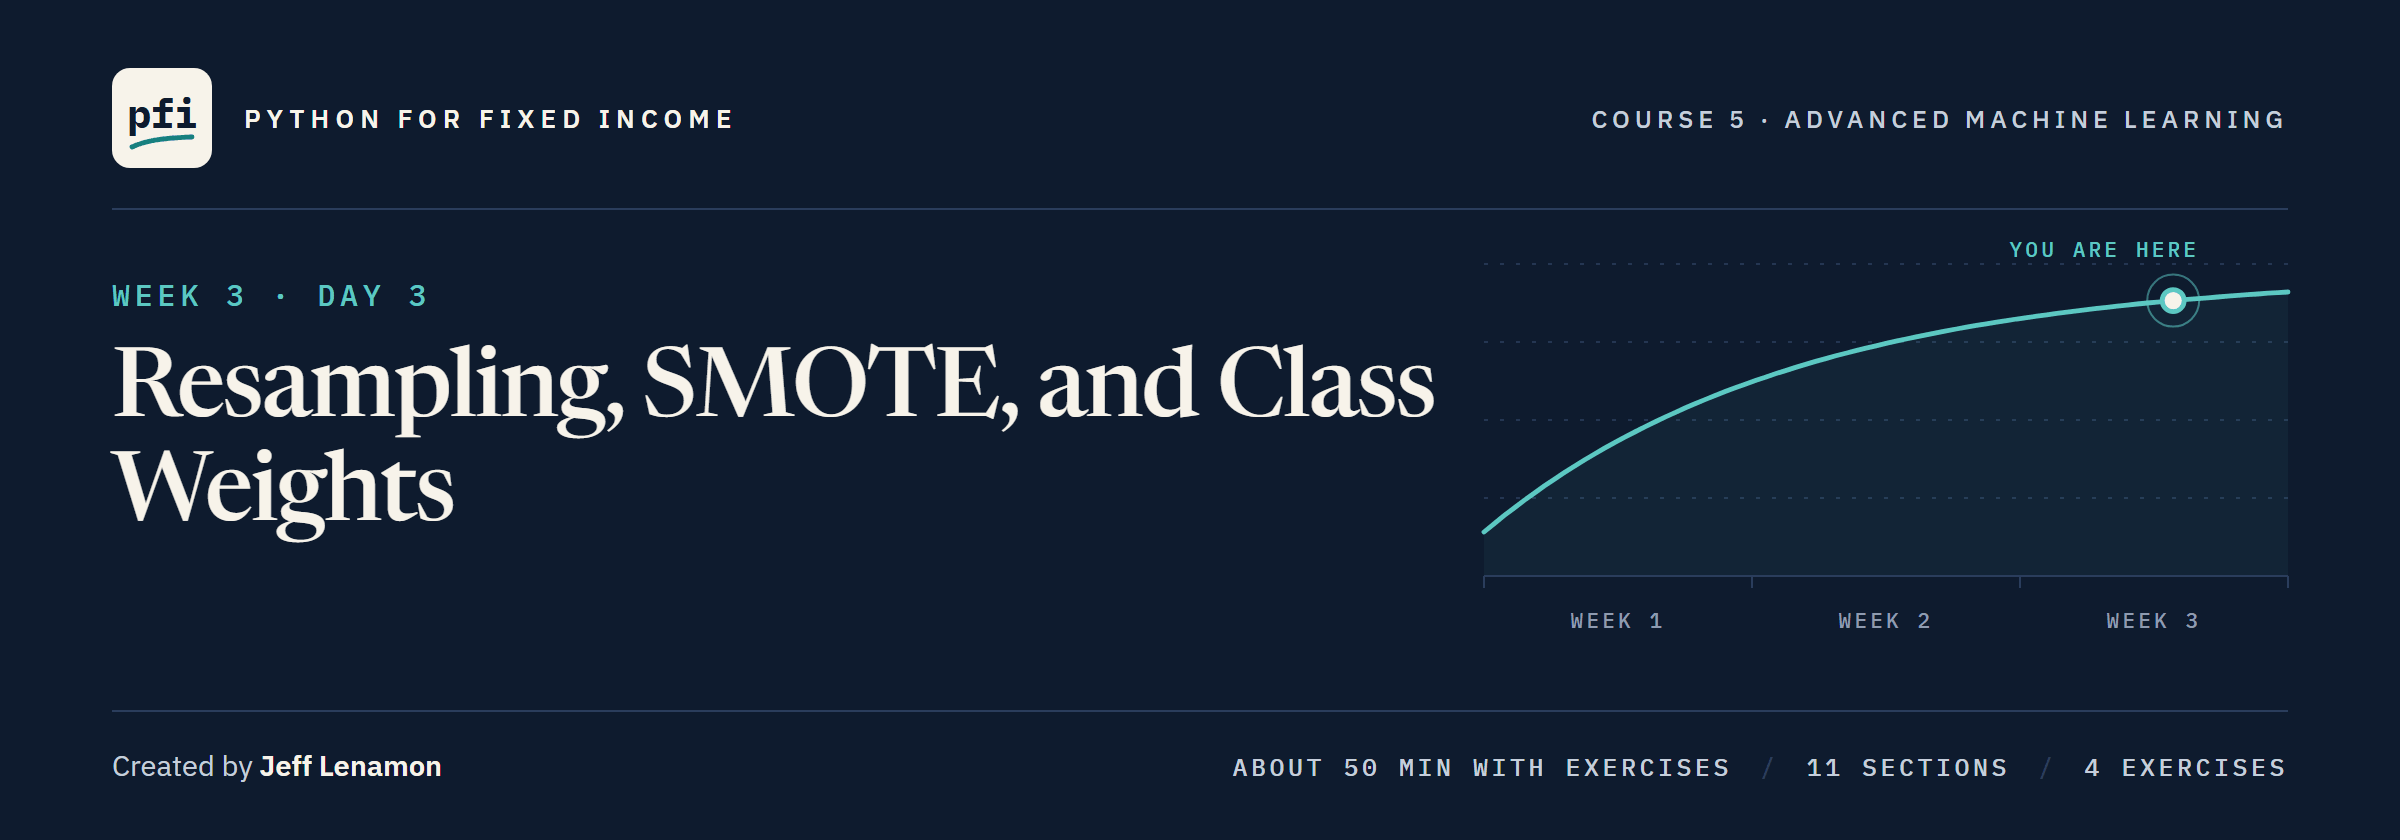

# Resampling, SMOTE, and Class Weights

Week 3, Day 3. Weight the rare class, resample it three ways inside the folds, and measure what each fix does to the ranking, to the flags at 0.5, and to what the output adds up to.

**Data:** `polish_bankruptcy_5year.csv`, 5,910 financial statements of Polish companies: **real**, UCI Machine Learning Repository dataset 365, CC BY 4.0. Citation: Tomczak, S. (2016). Polish Companies Bankruptcy [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F600.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day3/13_resampling_smote_and_class_weights.ipynb)

# Problem Statement

## Business Context

Of the 4,680 Polish companies in the training rows, 326 went bankrupt within a year: about 13 healthy companies for every bankrupt one.
Tutorials and AI answers give the same advice for a file like this: fix the imbalance before you fit.
Weight the rare class, copy it, drop some of the common class, or make up new rare rows.
Course 4's capstone took the first route, and its logistic regression carries `class_weight="balanced"`.
Day 12 handed over two models: LightGBM at its defaults, at a fold average precision of 0.7783, and that logistic pipeline, at 0.6624.
The colleague who brought the file asks three questions: does a fix help either model rank, what does it do to the output, and can the output still be read as a probability?
The dataset page dates the companies from 2000 to 2013 ([dataset page](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data)), one country in one period.
An unweighted model's output is the model's probability of bankruptcy in this file; a weighted or resampled model's output is the model's score.

## Objectives

Weight the rare class with class weights, resample the rows three ways and count what each leaves, and build one synthetic row by hand.
Score weighted, resampled and unweighted models on the same folds and at one recall, measure what each fix does to a model's output, and turn a score back into a probability two ways.

## Data Dictionary

`polish_bankruptcy_5year.csv`, one row per financial statement:

1. `Attr1` to `Attr64`: the page's X1 to X64, ratios from the statements
2. `class`: 1 if the company went bankrupt within a year, **the target**

Two ratios are drawn by name, as the page defines them:

- `Attr2`: total liabilities / total assets
- `Attr7`: EBIT / total assets

## Your Route Through Day 3

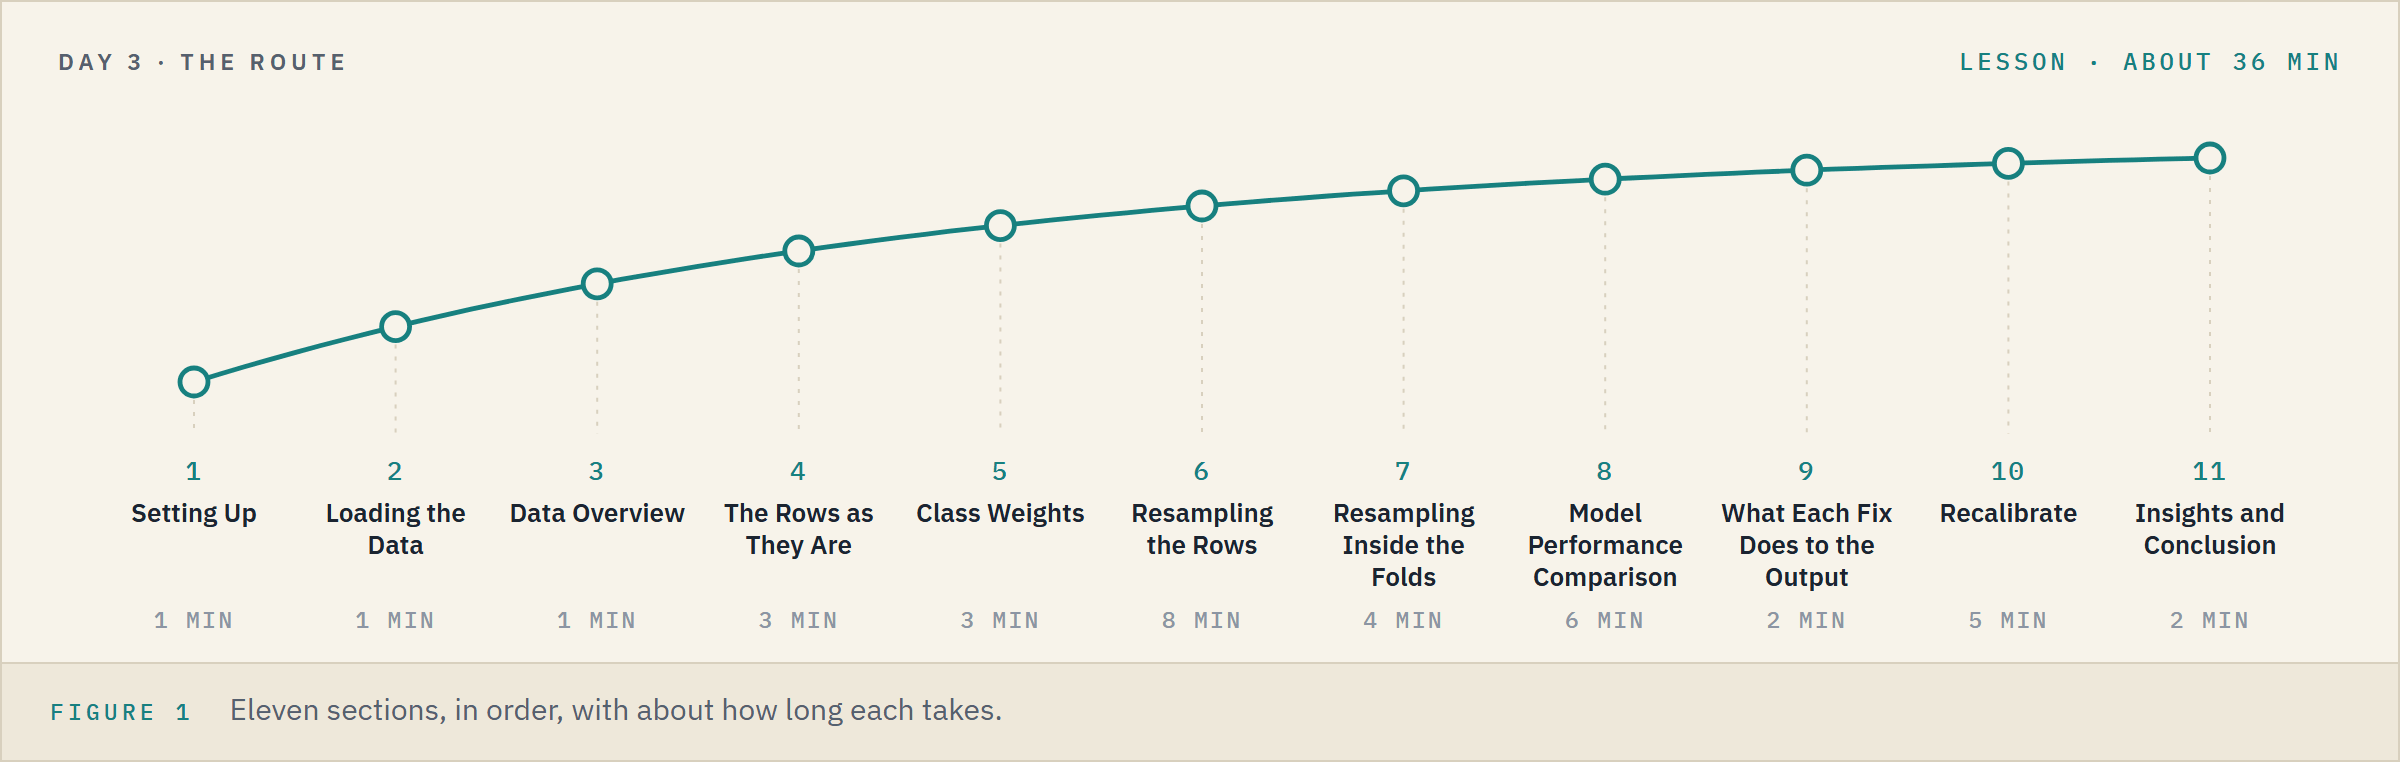

**Time.** About 36 minutes for the lesson, then about 12 for the four exercises.

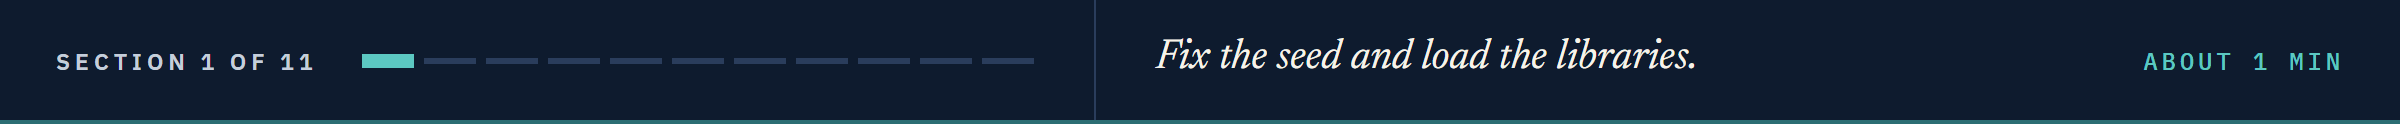

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and two sliders
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split and fold the rows, and score on the folds
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict

# Course 4's logistic pipeline, and the booster
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

# Day 3's forest, for an exercise
from sklearn.ensemble import RandomForestClassifier

# today's tools: three samplers, the pipeline that runs them, a neighbour finder, and a calibrator
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.neighbors import NearestNeighbors
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

# to score the outputs
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix, brier_score_loss

# one look for every chart, Course 4's four confusion-matrix colours, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

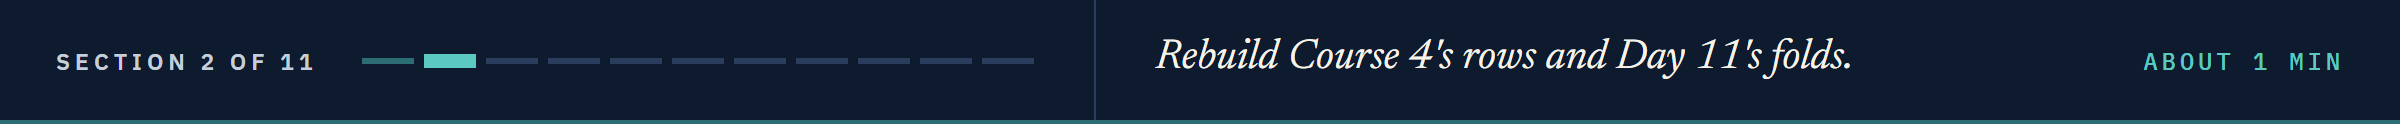

# Loading the Data

## Course 4's Rows, Day 11's Folds

In [3]:
# the 5,910 statements: 64 ratios named Attr1 to Attr64, and the outcome in class
bankrupt = pd.read_csv(DATA + "polish_bankruptcy_5year.csv")
TARGET = "class"
FEATURES = [column for column in bankrupt.columns if column != TARGET]

# Course 4's capstone: the exact copies out, then one stratified 80/20 split with the course seed
unique = bankrupt.drop_duplicates()
X_train, X_test, y_train, y_test = train_test_split(unique[FEATURES], unique[TARGET], test_size=0.2,
                                                    stratify=unique[TARGET], random_state=SEED)
print(len(bankrupt), "read,", len(unique), "unique.  Training:", len(X_train), "rows,", y_train.sum(), "bankrupt")

5910 read, 5850 unique.  Training: 4680 rows, 326 bankrupt


In [4]:
# Day 11's five stratified folds, and a True for each training company that went bankrupt
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
went = y_train.to_numpy() == 1

The same 4,680 training rows as Course 4's capstone and Days 11 and 12.

The 1,170 test rows are never scored in Course 5.

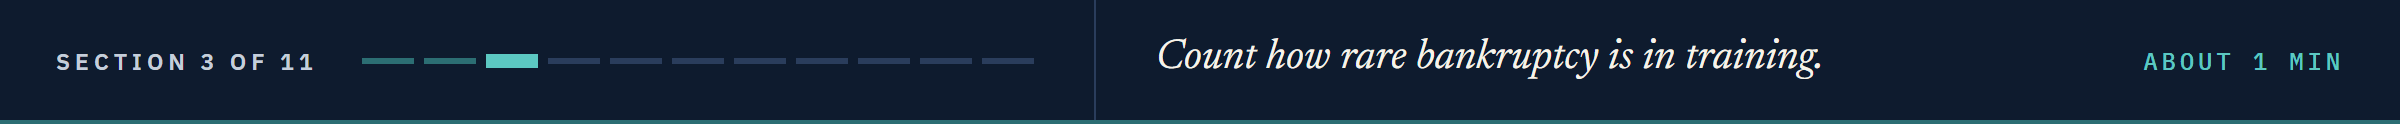

# Data Overview

## How Rare Is Rare

In [5]:
# companies by outcome, healthy ones per bankrupt one, and the share right if nobody is flagged
counts = y_train.value_counts()
print(counts.to_dict(), " Healthy per bankrupt:", round(counts[0] / counts[1], 1))
print("Right if nobody is flagged:", round(counts[0] / len(y_train), 4), " Bankrupt share:", round(y_train.mean(), 4))

{0: 4354, 1: 326}  Healthy per bankrupt: 13.4
Right if nobody is flagged: 0.9303  Bankrupt share: 0.0697


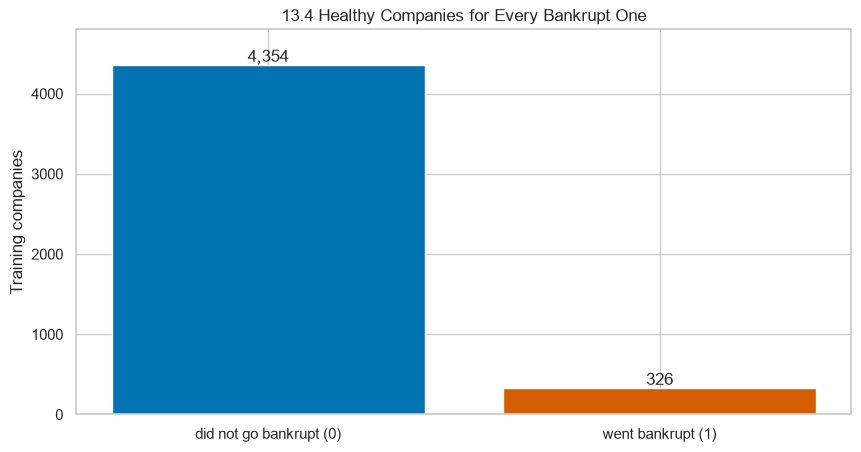

In [6]:
# the two outcomes as bars, each labelled with its count
bars = plt.bar(["did not go bankrupt (0)", "went bankrupt (1)"], counts.values, color=["C0", "C3"])
plt.bar_label(bars, fmt="{:,.0f}")
plt.ylim(0, 4800)
plt.ylabel("Training companies")
plt.title("13.4 Healthy Companies for Every Bankrupt One")
plt.show()

A model that flags nobody is right on 93.03 percent of the companies and catches none of the 326.

So accuracy cannot choose between models here.

**Average precision ranks the models, and recall at a stated threshold counts the catches, as all week.**

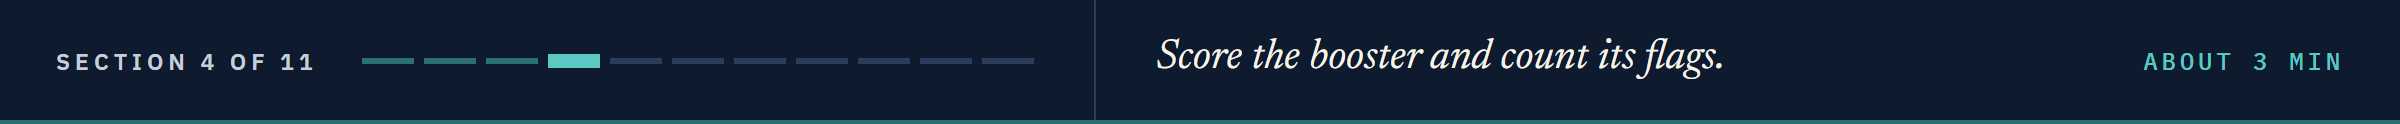

# The Rows as They Are

## LightGBM at Its Defaults

In [7]:
# Day 11's booster at its defaults, scored on the five folds as Day 11 scored it
booster = LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1)
booster_cv = cross_validate(booster, X_train, y_train, cv=folds, scoring="average_precision", n_jobs=1)
print("Folds:", booster_cv["test_score"].round(4), " Mean:", round(booster_cv["test_score"].mean(), 4))

Folds: [0.7077 0.7988 0.7434 0.8013 0.8405]  Mean: 0.7783


## Out-of-Fold Outputs

Course 4's capstone gave each training company the output of the fit that never saw it, with `cross_val_predict`.
Today every model is scored from those out-of-fold outputs: each fold's average precision is read from its own 936 companies.

In [8]:
# each training company's out-of-fold output, as Course 4's capstone made them
def out_of_fold(model):
    return cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba", n_jobs=1)[:, 1]

# each fold's average precision, read from the out-of-fold outputs of that fold's companies
def fold_ap(output):
    return np.array([average_precision_score(y_train.iloc[held], output[held]) for fit, held in folds.split(X_train, y_train)])

plain = out_of_fold(booster)
print("Folds:", fold_ap(plain).round(4), " Mean:", round(fold_ap(plain).mean(), 4))

Folds: [0.7077 0.7988 0.7434 0.8013 0.8405]  Mean: 0.7783


The same five numbers as `cross_validate`, from the same five fits.

## The Flags at 0.5

`.predict` flags a company when its output reaches 0.5, the cut most tutorials leave in place.

In [9]:
# the flags at 0.5: flagged, bankruptcies caught, bankruptcies missed
flags = plain >= 0.5
print("Flagged:", flags.sum(), " Caught:", (flags & went).sum(), "of 326  Missed:", (~flags & went).sum())

Flagged: 222  Caught: 191 of 326  Missed: 135


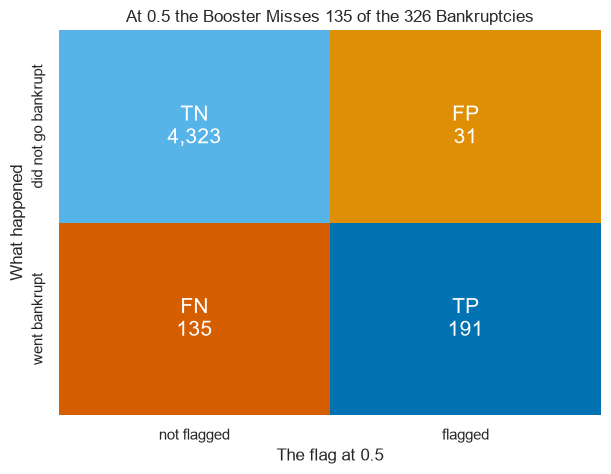

In [10]:
# the confusion matrix at 0.5 in Course 4's four colours, each cell with its name and count
tn, fp, fn, tp = confusion_matrix(went, flags).ravel()
labels = [[f"TN\n{tn:,}", f"FP\n{fp:,}"], [f"FN\n{fn:,}", f"TP\n{tp:,}"]]
plt.figure(figsize=(7, 5))
sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, annot_kws={"size": 15},
            xticklabels=["not flagged", "flagged"], yticklabels=["did not go bankrupt", "went bankrupt"])
plt.xlabel("The flag at 0.5")
plt.ylabel("What happened")
plt.title("At 0.5 the Booster Misses 135 of the 326 Bankruptcies")
plt.show()

At 0.5 the booster catches 191 of the 326 bankruptcies, with 31 false flags.

**At the default cut the model misses four bankruptcies in ten: the problem the advice promises to fix.**

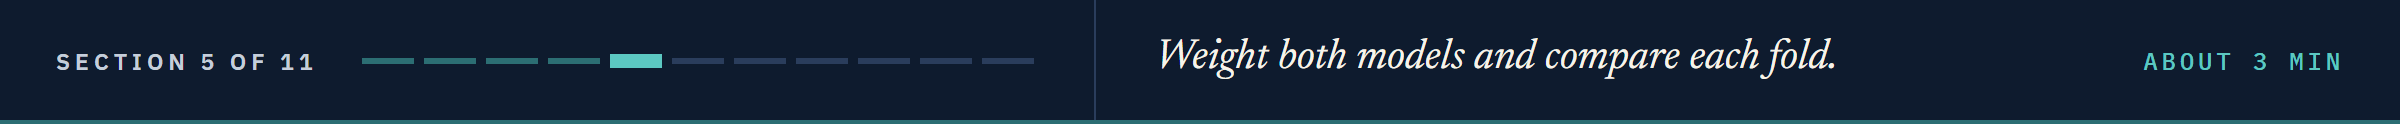

# Class Weights

## What Balanced Weights Are

Course 4's Day 9 balanced its tree with `class_weight="balanced"`, and Day 8 weighted XGBoost with `scale_pos_weight` and watched its outputs rise.
A balanced weight is the rows over twice the class's rows, so each class carries half the total weight.

In [11]:
# Course 4's Day 9 rule: rows over (2 x the class's rows), and each class's total weight
weights = len(y_train) / (2 * counts)
print("Weights:", weights.round(4).to_dict(), " Totals:", (weights * counts).round(1).to_dict())

Weights: {0: 0.5374, 1: 7.1779}  Totals: {0: 2340.0, 1: 2340.0}


Each bankrupt company counts 7.18 times, each healthy one about half a time.

The fit sees the classes as if half the companies had gone bankrupt.

## LightGBM, Balanced

In [12]:
# the same booster with balanced weights, on the same folds, and its flags at 0.5
balanced = out_of_fold(LGBMClassifier(class_weight="balanced", random_state=SEED, n_jobs=1, verbose=-1))
print("Fold mean:", round(fold_ap(balanced).mean(), 4), " At 0.5, flagged:", (balanced >= 0.5).sum(),
      " caught:", ((balanced >= 0.5) & went).sum())

Fold mean: 0.7704  At 0.5, flagged: 258  caught: 201


At 0.5 it flags 258 companies and catches 201 bankruptcies, against 191.

Its fold average precision is lower, 0.7704 against 0.7783: the ranking did not improve.

**Predict 1**

Course 4's chosen logistic pipeline carries balanced weights and scores 0.6624.

Q. Take the weights out and change nothing else. Write down its fold average precision.

## Course 4's Logistic, Without Its Weights

In [13]:
# Course 4's pipeline, with or without class weights
def logistic(weights=None):
    return Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                     ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                     ("logit", LogisticRegression(solver="newton-cholesky", tol=1e-8, class_weight=weights))])

course4 = out_of_fold(logistic("balanced"))
unweighted = out_of_fold(logistic())
print("Balanced (Course 4):", round(fold_ap(course4).mean(), 4), " Unweighted:", round(fold_ap(unweighted).mean(), 4))

Balanced (Course 4): 0.6624  Unweighted: 0.6926


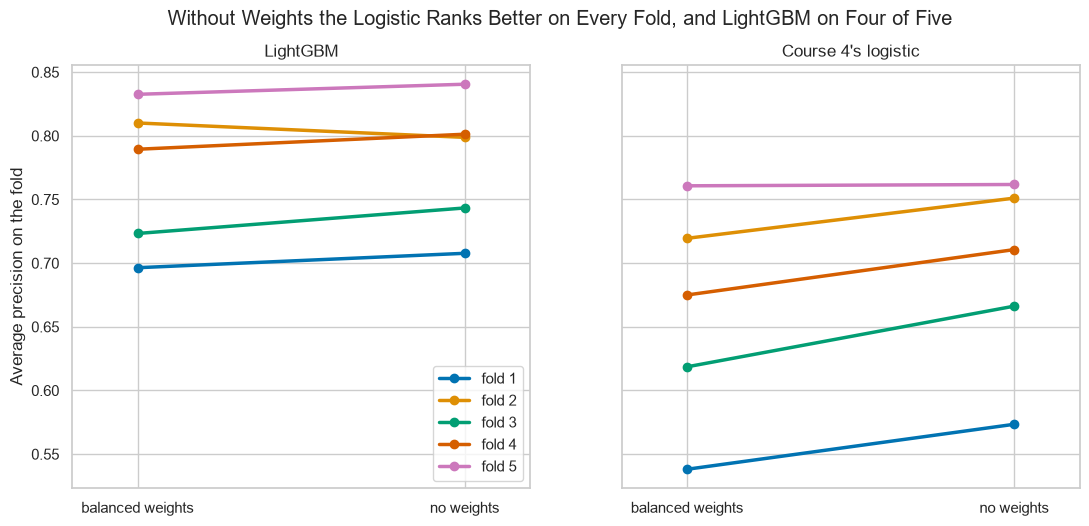

In [14]:
# one line per fold, balanced on the left and unweighted on the right, for each model
pairs = {"LightGBM": (balanced, plain), "Course 4's logistic": (course4, unweighted)}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, name in zip(axes, pairs):
    for fold, (left, right) in enumerate(zip(fold_ap(pairs[name][0]), fold_ap(pairs[name][1])), start=1):
        ax.plot([0, 1], [left, right], marker="o", linewidth=2.5, label="fold " + str(fold))
    ax.set(xticks=[0, 1], xticklabels=["balanced weights", "no weights"], xlim=(-0.2, 1.2), title=name)
axes[0].set_ylabel("Average precision on the fold")
axes[0].legend(loc="lower right")
fig.suptitle("Without Weights the Logistic Ranks Better on Every Fold, and LightGBM on Four of Five")
plt.show()

Without its weights Course 4's logistic scores 0.6926 against 0.6624, higher on all five folds.

That is a finding about this file: the capstone's weights cost its chosen model 0.03 of average precision.

**On both models the unweighted fit ranks as well or better; the weights only moved where 0.5 falls.**

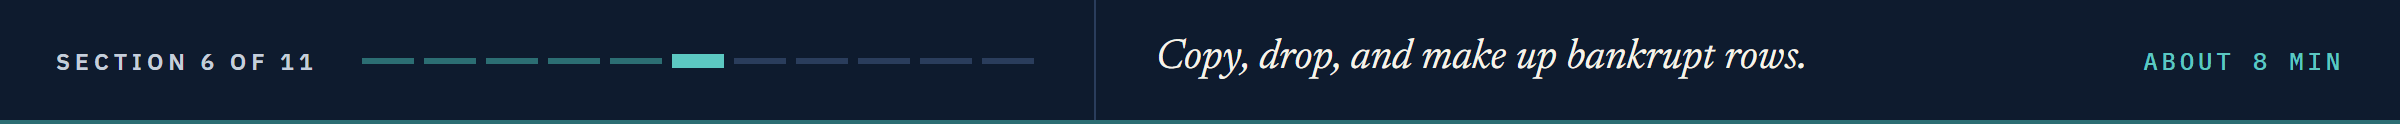

# Resampling the Rows

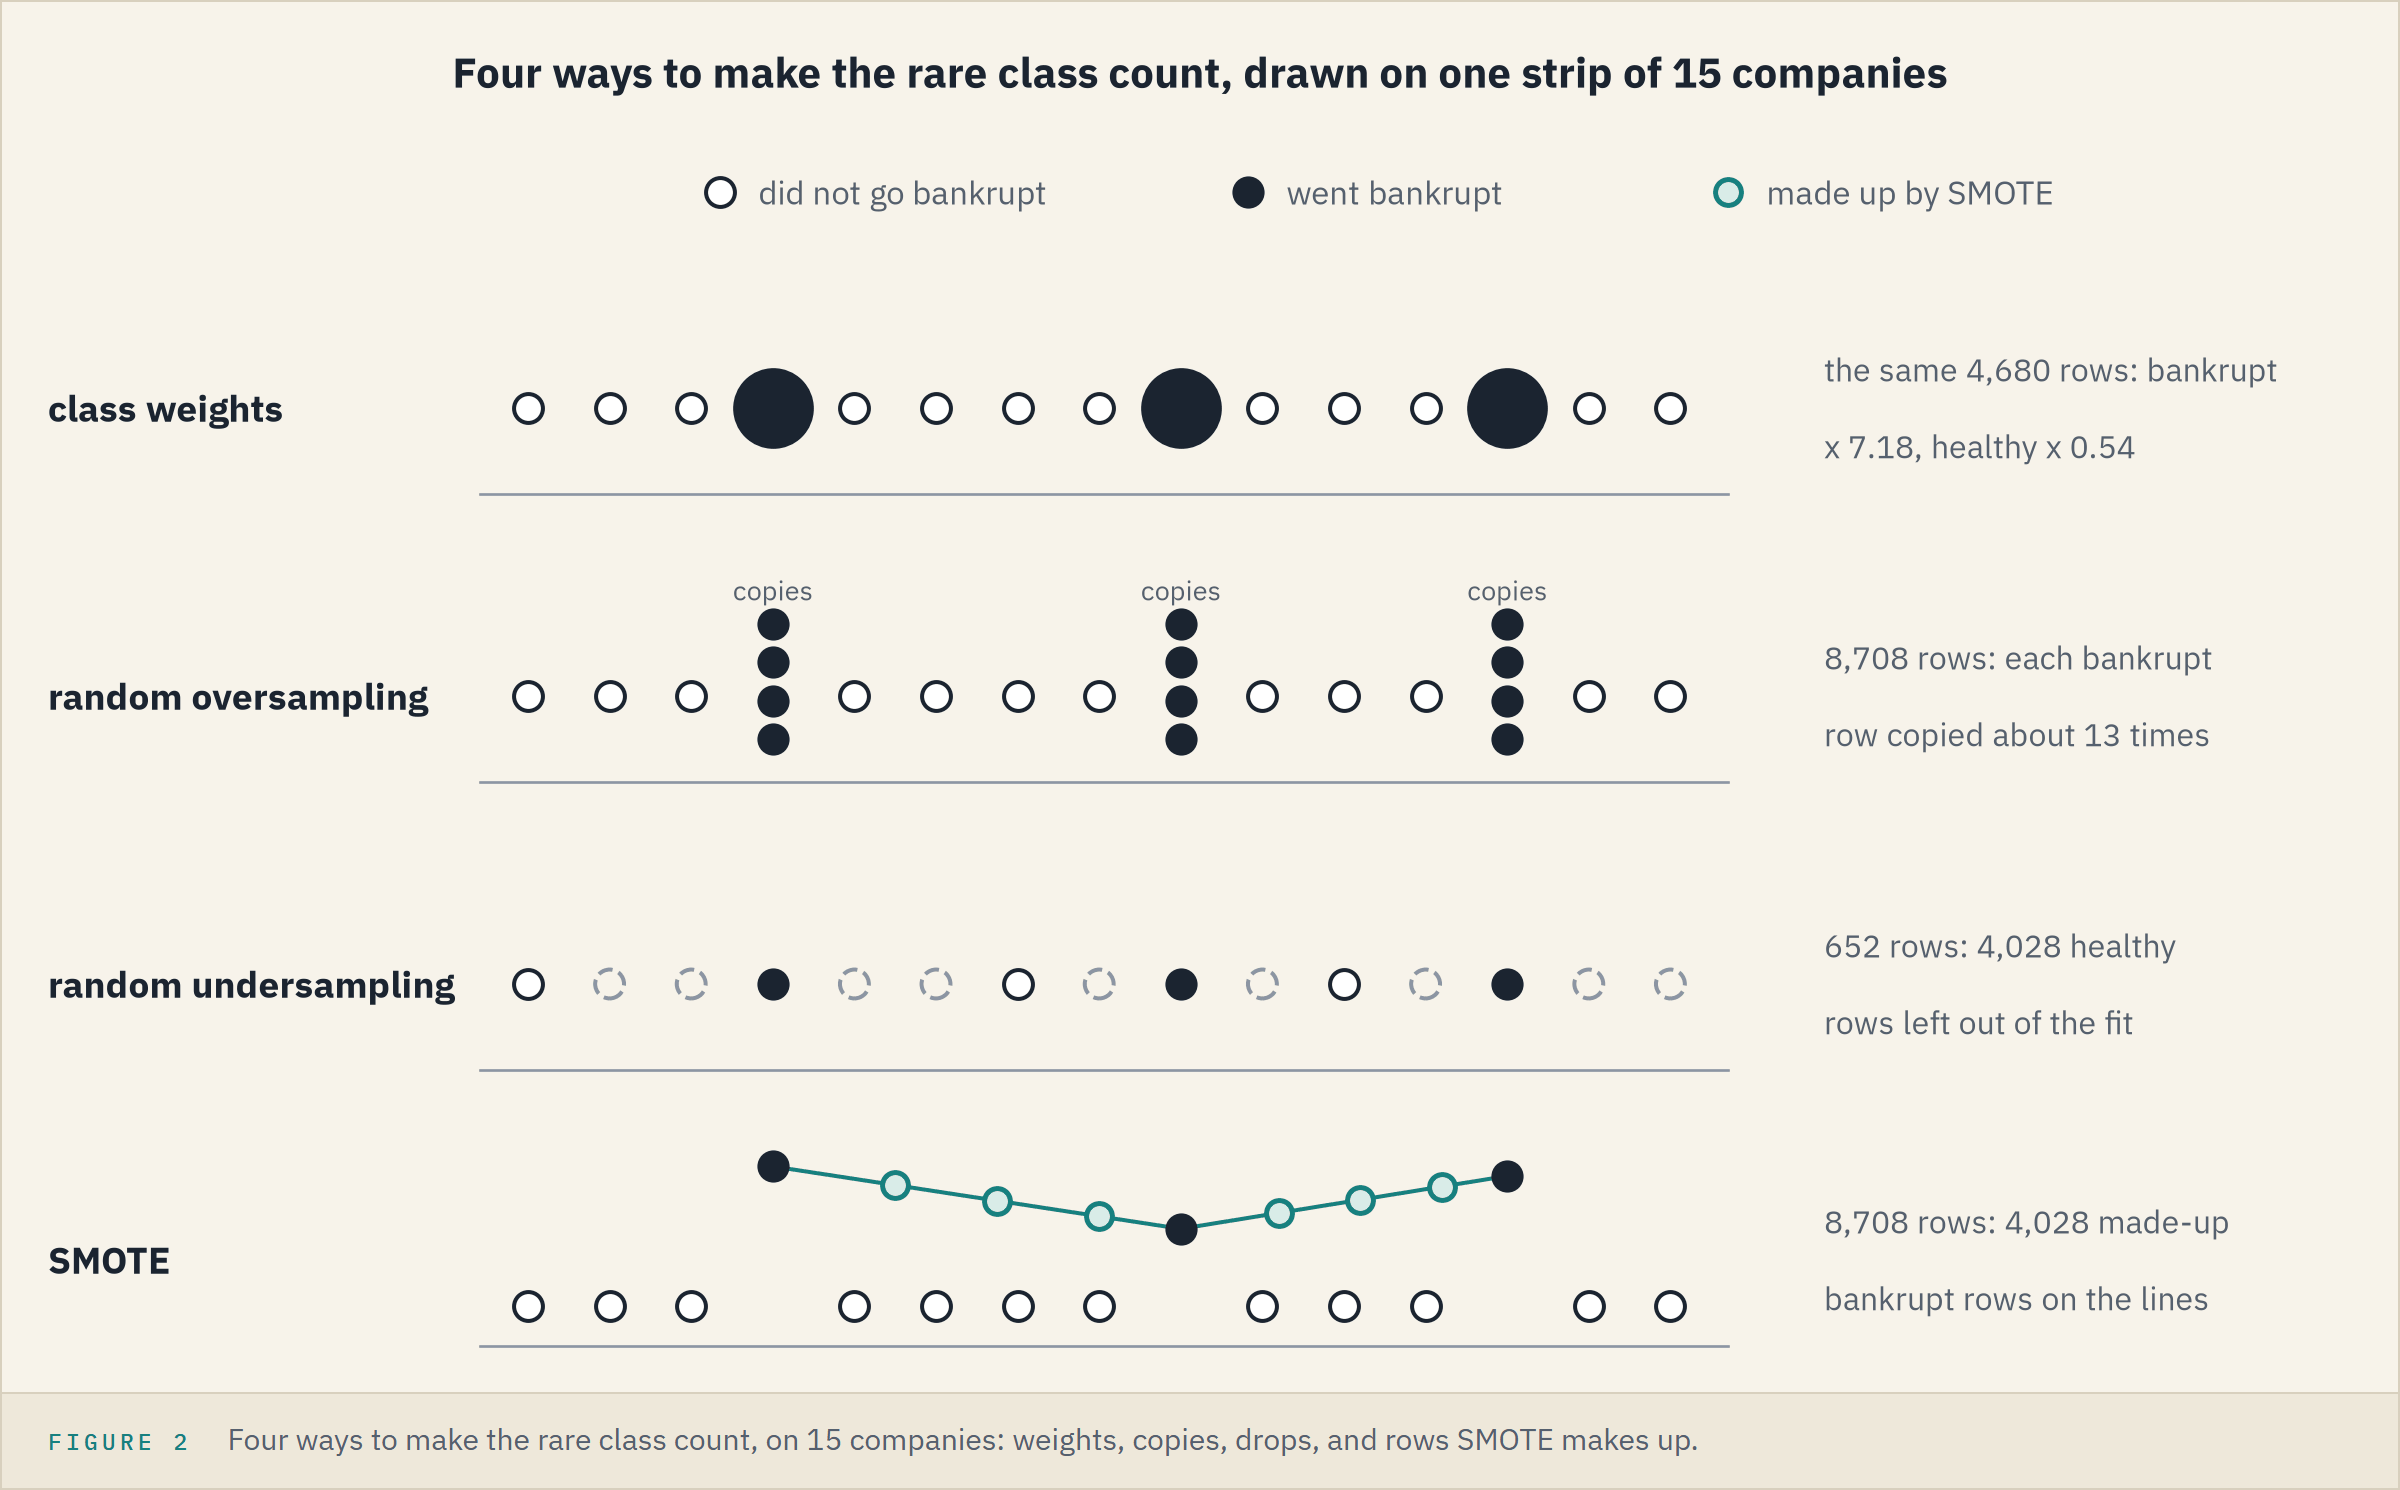

Weights keep the rows and change what each counts.
Resampling changes the rows: copy bankrupt companies, drop healthy ones, or make up new bankrupt ones.
Course 4's Day 10 AI check caught defaults copied before the split.

## Copies and Drops

imbalanced-learn is a library of **samplers**, steps that change the rows of a fit.
`RandomOverSampler` copies rows of the rare class at random, and `RandomUnderSampler` drops rows of the common class at random, until the classes are equal.
`ImbPipeline` is imbalanced-learn's copy of scikit-learn's `Pipeline` that accepts a sampler as a step, and `.fit_resample(X, y)` returns the rows a sampler makes.

In [15]:
# a demonstration: each sampler's rows, counted by outcome
copied = ImbPipeline([("copy", RandomOverSampler(random_state=SEED))]).fit_resample(X_train, y_train)[1]
dropped = ImbPipeline([("drop", RandomUnderSampler(random_state=SEED))]).fit_resample(X_train, y_train)[1]
resampled = pd.DataFrame({"as they are": counts, "copied": copied.value_counts(), "dropped": dropped.value_counts()})
resampled

,as they are,copied,dropped
class,,,
0,4354,4354,326
1,326,4354,326


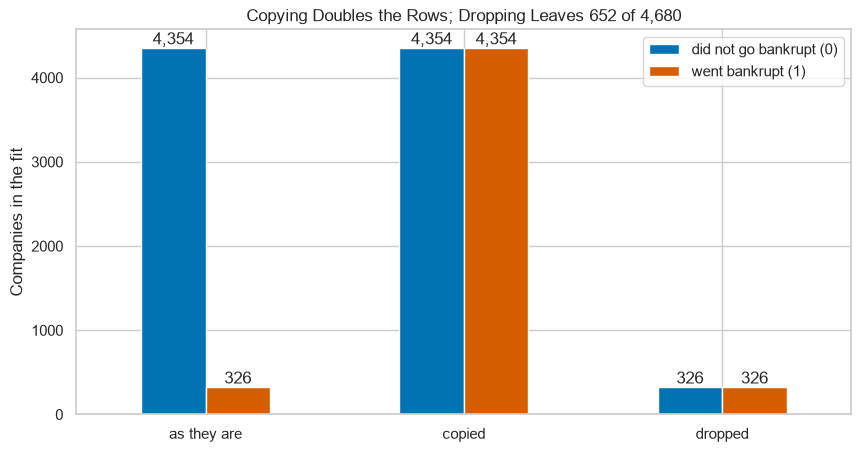

In [16]:
# the three sets of rows as grouped bars, each bar labelled
ax = resampled.T.plot.bar(rot=0, color=["C0", "C3"], figsize=(10, 5))
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:,.0f}")
ax.set(ylabel="Companies in the fit", title="Copying Doubles the Rows; Dropping Leaves 652 of 4,680")
ax.legend(["did not go bankrupt (0)", "went bankrupt (1)"], loc="upper right")
plt.show()

Copying fits 8,708 rows, each bankrupt company about 13 times.

Dropping fits 652 rows and throws away 4,028 healthy companies.

## One Made-Up Company, by Hand

A third sampler makes up bankrupt companies that never existed.
Take one bankrupt company, find its five nearest bankrupt companies, pick one, and put a new company at a random point on the line between the two.
`NearestNeighbors(n_neighbors=6)` finds, for each row, the six rows nearest it in straight-line distance, and `.kneighbors(rows)` returns their distances and positions.

In [17]:
# a demonstration on two ratios, gaps filled with the medians: every company, and the bankrupt ones
two = ["Attr2", "Attr7"]
real = X_train[two].fillna(X_train[two].median()).to_numpy()
sick = real[went]

# each bankrupt company's nearest bankrupt companies: the first found is the company itself
near = NearestNeighbors(n_neighbors=6).fit(sick).kneighbors(sick)[1]
pick = 5
print("Company:", sick[pick], " Its five neighbours:", near[pick, 1:])

Company: [ 0.98042 -0.3811 ]  Its five neighbours: [112 315  75 104 111]


In [18]:
# one neighbour at random, one point at random on the line to it: new row = x + u * (neighbour - x)
rng = np.random.default_rng(SEED)
x = sick[pick]
neighbour = sick[near[pick, rng.integers(1, 6)]]
u = rng.random()
new_row = x + u * (neighbour - x)
print("Neighbour:", neighbour, " u:", round(u, 4), " New row:", new_row.round(4))

Neighbour: [ 0.99933 -0.34226]  u: 0.4389  New row: [ 0.9887 -0.3641]


The new company sits 44 percent of the way from the bankrupt company to its neighbour, on both ratios at once.

That is **SMOTE**, synthetic minority oversampling: it repeats this step until the bankrupt companies match the healthy ones.

`SMOTE(k_neighbors=5)` is the default: five neighbours to choose from.

## SMOTE Needs Every Gap Filled

In [19]:
# a demonstration: SMOTE on the 64 ratios as they are
ImbPipeline([("smote", SMOTE(random_state=SEED))]).fit_resample(X_train, y_train)

ValueError: Input X contains NaN.
SMOTE does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

A distance needs a number in every column, and 48 columns have gaps (Day 11).

So SMOTE goes after an imputer, and its fair comparison is Day 12's LightGBM on median-filled rows, not the booster on the gaps.

## Where SMOTE Puts Its Rows

In [20]:
# a demonstration: the median imputer, then SMOTE with k neighbours, on the two ratios; the made-up rows come after the real ones
def smote_map(k, ax, xlim=(0, 1.5), ylim=(-0.6, 0.4)):
    rows = ImbPipeline([("impute", SimpleImputer(strategy="median")), ("smote", SMOTE(k_neighbors=k, random_state=SEED))]).fit_resample(X_train[two], y_train)[0]
    made = rows[len(X_train):]
    healthy_nearest = ~went[NearestNeighbors(n_neighbors=1).fit(real).kneighbors(made)[1][:, 0]]
    ax.scatter(real[~went, 0], real[~went, 1], s=6, color="lightgray", label="did not go bankrupt")
    ax.scatter(made[:, 0], made[:, 1], s=14, marker="x", color="C0", alpha=0.6, label="made up by SMOTE")
    ax.scatter(sick[:, 0], sick[:, 1], s=22, color="C3", label="went bankrupt")
    for p in NearestNeighbors(n_neighbors=k + 1).fit(sick).kneighbors(sick[[pick]])[1][0, 1:]:
        ax.plot([x[0], sick[p, 0]], [x[1], sick[p, 1]], color="black", linewidth=1.2)
    ax.set(xlim=xlim, ylim=ylim, xlabel="Attr2: total liabilities / total assets", ylabel="Attr7: EBIT / total assets")
    ax.set_title(f"k_neighbors={k}: {healthy_nearest.mean():.1%} of {len(made):,} made-up rows sit nearest a healthy company")

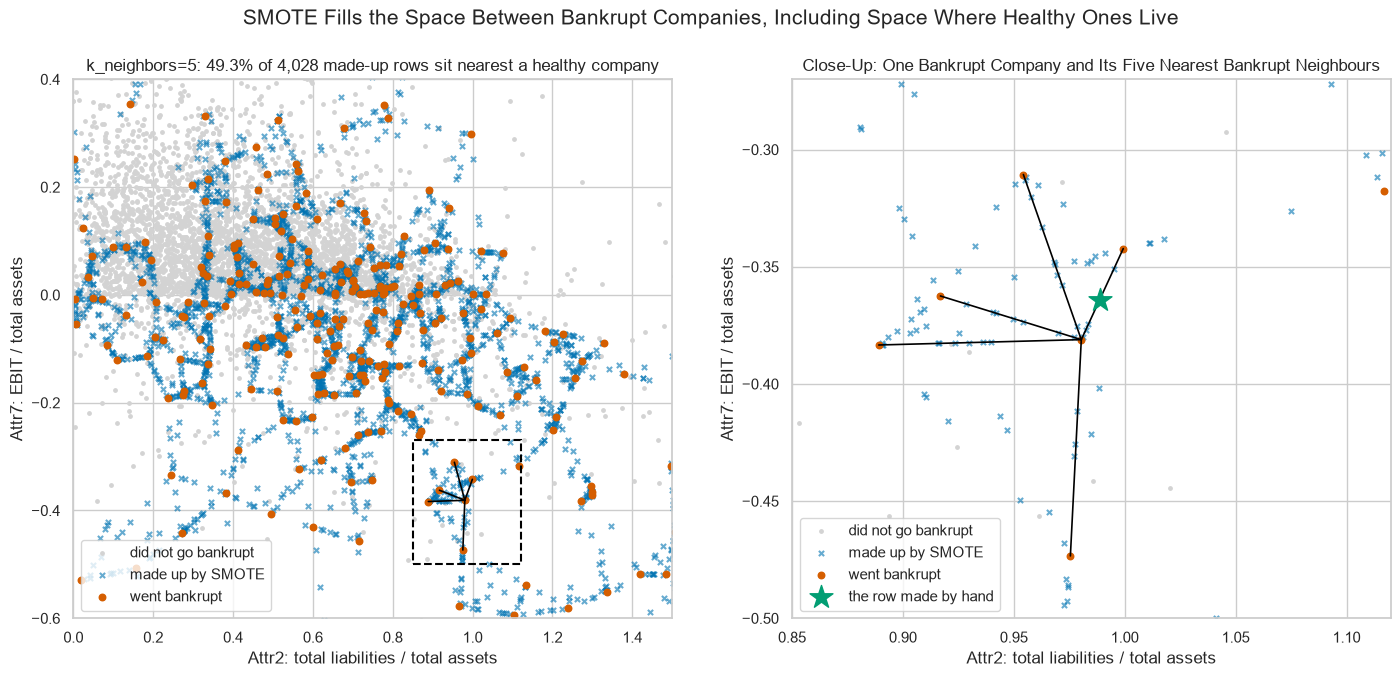

In [21]:
# the crowd with the close-up's window dashed, then the close-up: one company's five lines, the crosses, the row made by hand
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
smote_map(5, axes[0])
axes[0].add_patch(plt.Rectangle((0.85, -0.5), 0.27, 0.23, fill=False, edgecolor="black", linestyle="--", linewidth=1.5))
smote_map(5, axes[1], xlim=(0.85, 1.12), ylim=(-0.5, -0.27))
axes[1].scatter(new_row[0], new_row[1], s=300, marker="*", color="C2", zorder=4, label="the row made by hand")
axes[1].set_title("Close-Up: One Bankrupt Company and Its Five Nearest Bankrupt Neighbours")
axes[0].legend(loc="lower left")
axes[1].legend(loc="lower left")
fig.suptitle("SMOTE Fills the Space Between Bankrupt Companies, Including Space Where Healthy Ones Live", fontsize=15)
plt.show()

SMOTE made 4,028 bankrupt companies, so the classes match at 4,354.

Each cross lies on a line between two real bankrupt companies, as the hand-made row does.

About half of the made-up rows sit nearer a healthy company than a bankrupt one: SMOTE draws lines through the healthy crowd.

### Your Turn: Change the Neighbours

Slide `k_neighbors` and watch where the crosses land: more neighbours means longer lines.

In [22]:
# your turn: SMOTE refitted on the two ratios with k neighbours
def draw_smote(k_neighbors=5):
    fig, ax = plt.subplots(figsize=(10, 6.5))
    smote_map(k_neighbors, ax)
    ax.legend(loc="lower left")
    plt.show()

interact(draw_smote, k_neighbors=[1, 2, 3, 5, 10, 20]);

interactive(children=(Dropdown(description='k_neighbors', index=3, options=(1, 2, 3, 5, 10, 20), value=5), Out…

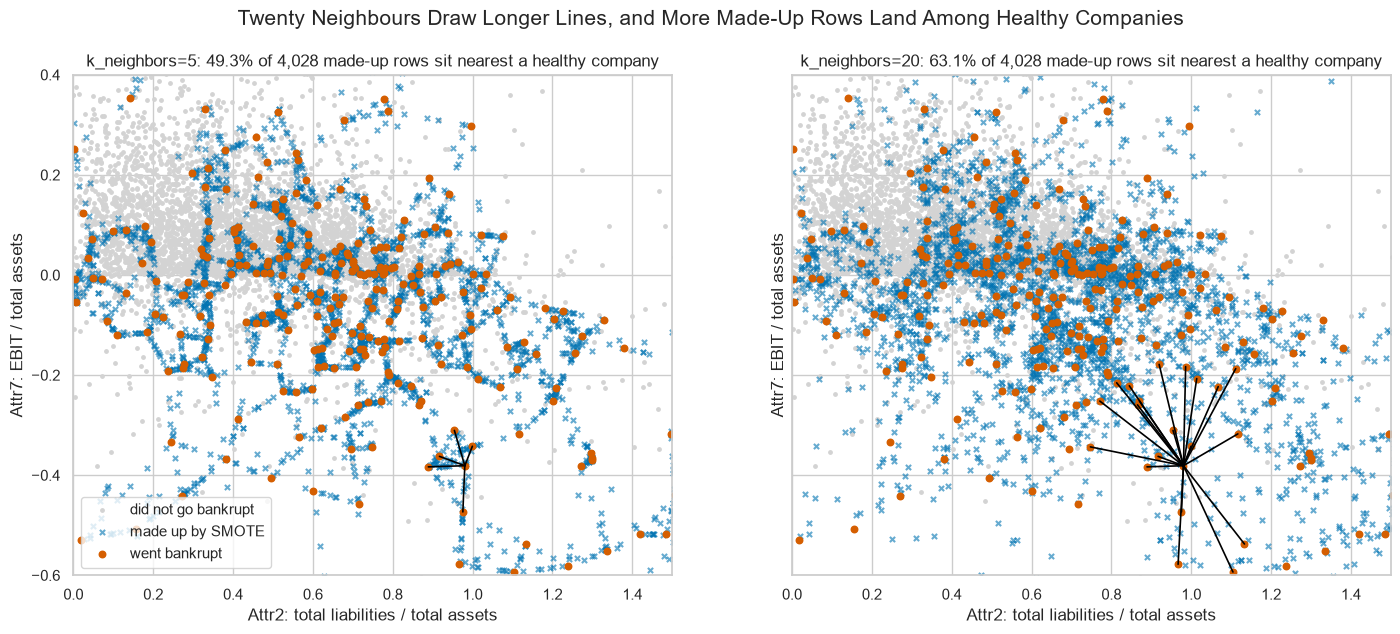

In [23]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub), beside 20 neighbours
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), sharey=True)
smote_map(5, axes[0])
smote_map(20, axes[1])
axes[0].legend(loc="lower left")
fig.suptitle("Twenty Neighbours Draw Longer Lines, and More Made-Up Rows Land Among Healthy Companies", fontsize=15)
plt.show()

With 20 neighbours, 63.1 percent of the made-up rows sit nearest a healthy company, against 49.3 percent with 5.

**SMOTE invents bankrupt companies between real ones, so where they land depends on distance: every gap filled first, and each column's scale decides who counts as near.**

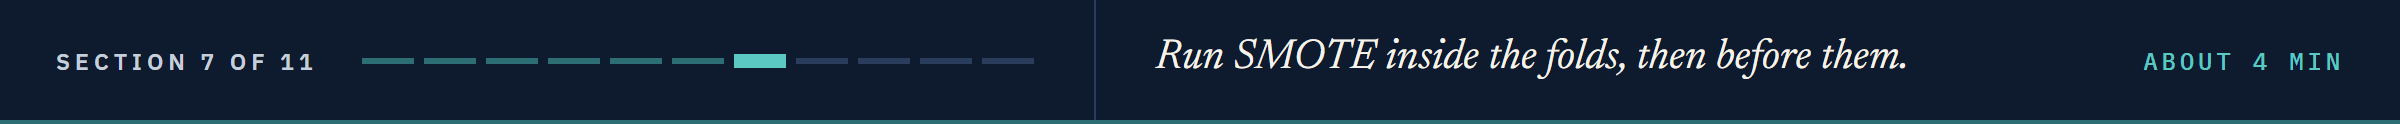

# Resampling Inside the Folds

## SMOTE Inside the Pipeline

In an `ImbPipeline` a sampler runs at fit only.
In each fold it makes rows from that fold's training part, and the held-out companies are scored as they are.

In [24]:
# Day 12's median-filled booster, and the same with SMOTE between the imputer and the model
filled = out_of_fold(Pipeline([("impute", SimpleImputer(strategy="median")), ("model", booster)]))
smote = out_of_fold(ImbPipeline([("impute", SimpleImputer(strategy="median")), ("smote", SMOTE(random_state=SEED)), ("model", booster)]))
print("Median fill:", round(fold_ap(filled).mean(), 4), " Median fill, then SMOTE:", round(fold_ap(smote).mean(), 4))

Median fill: 0.7561  Median fill, then SMOTE: 0.6239


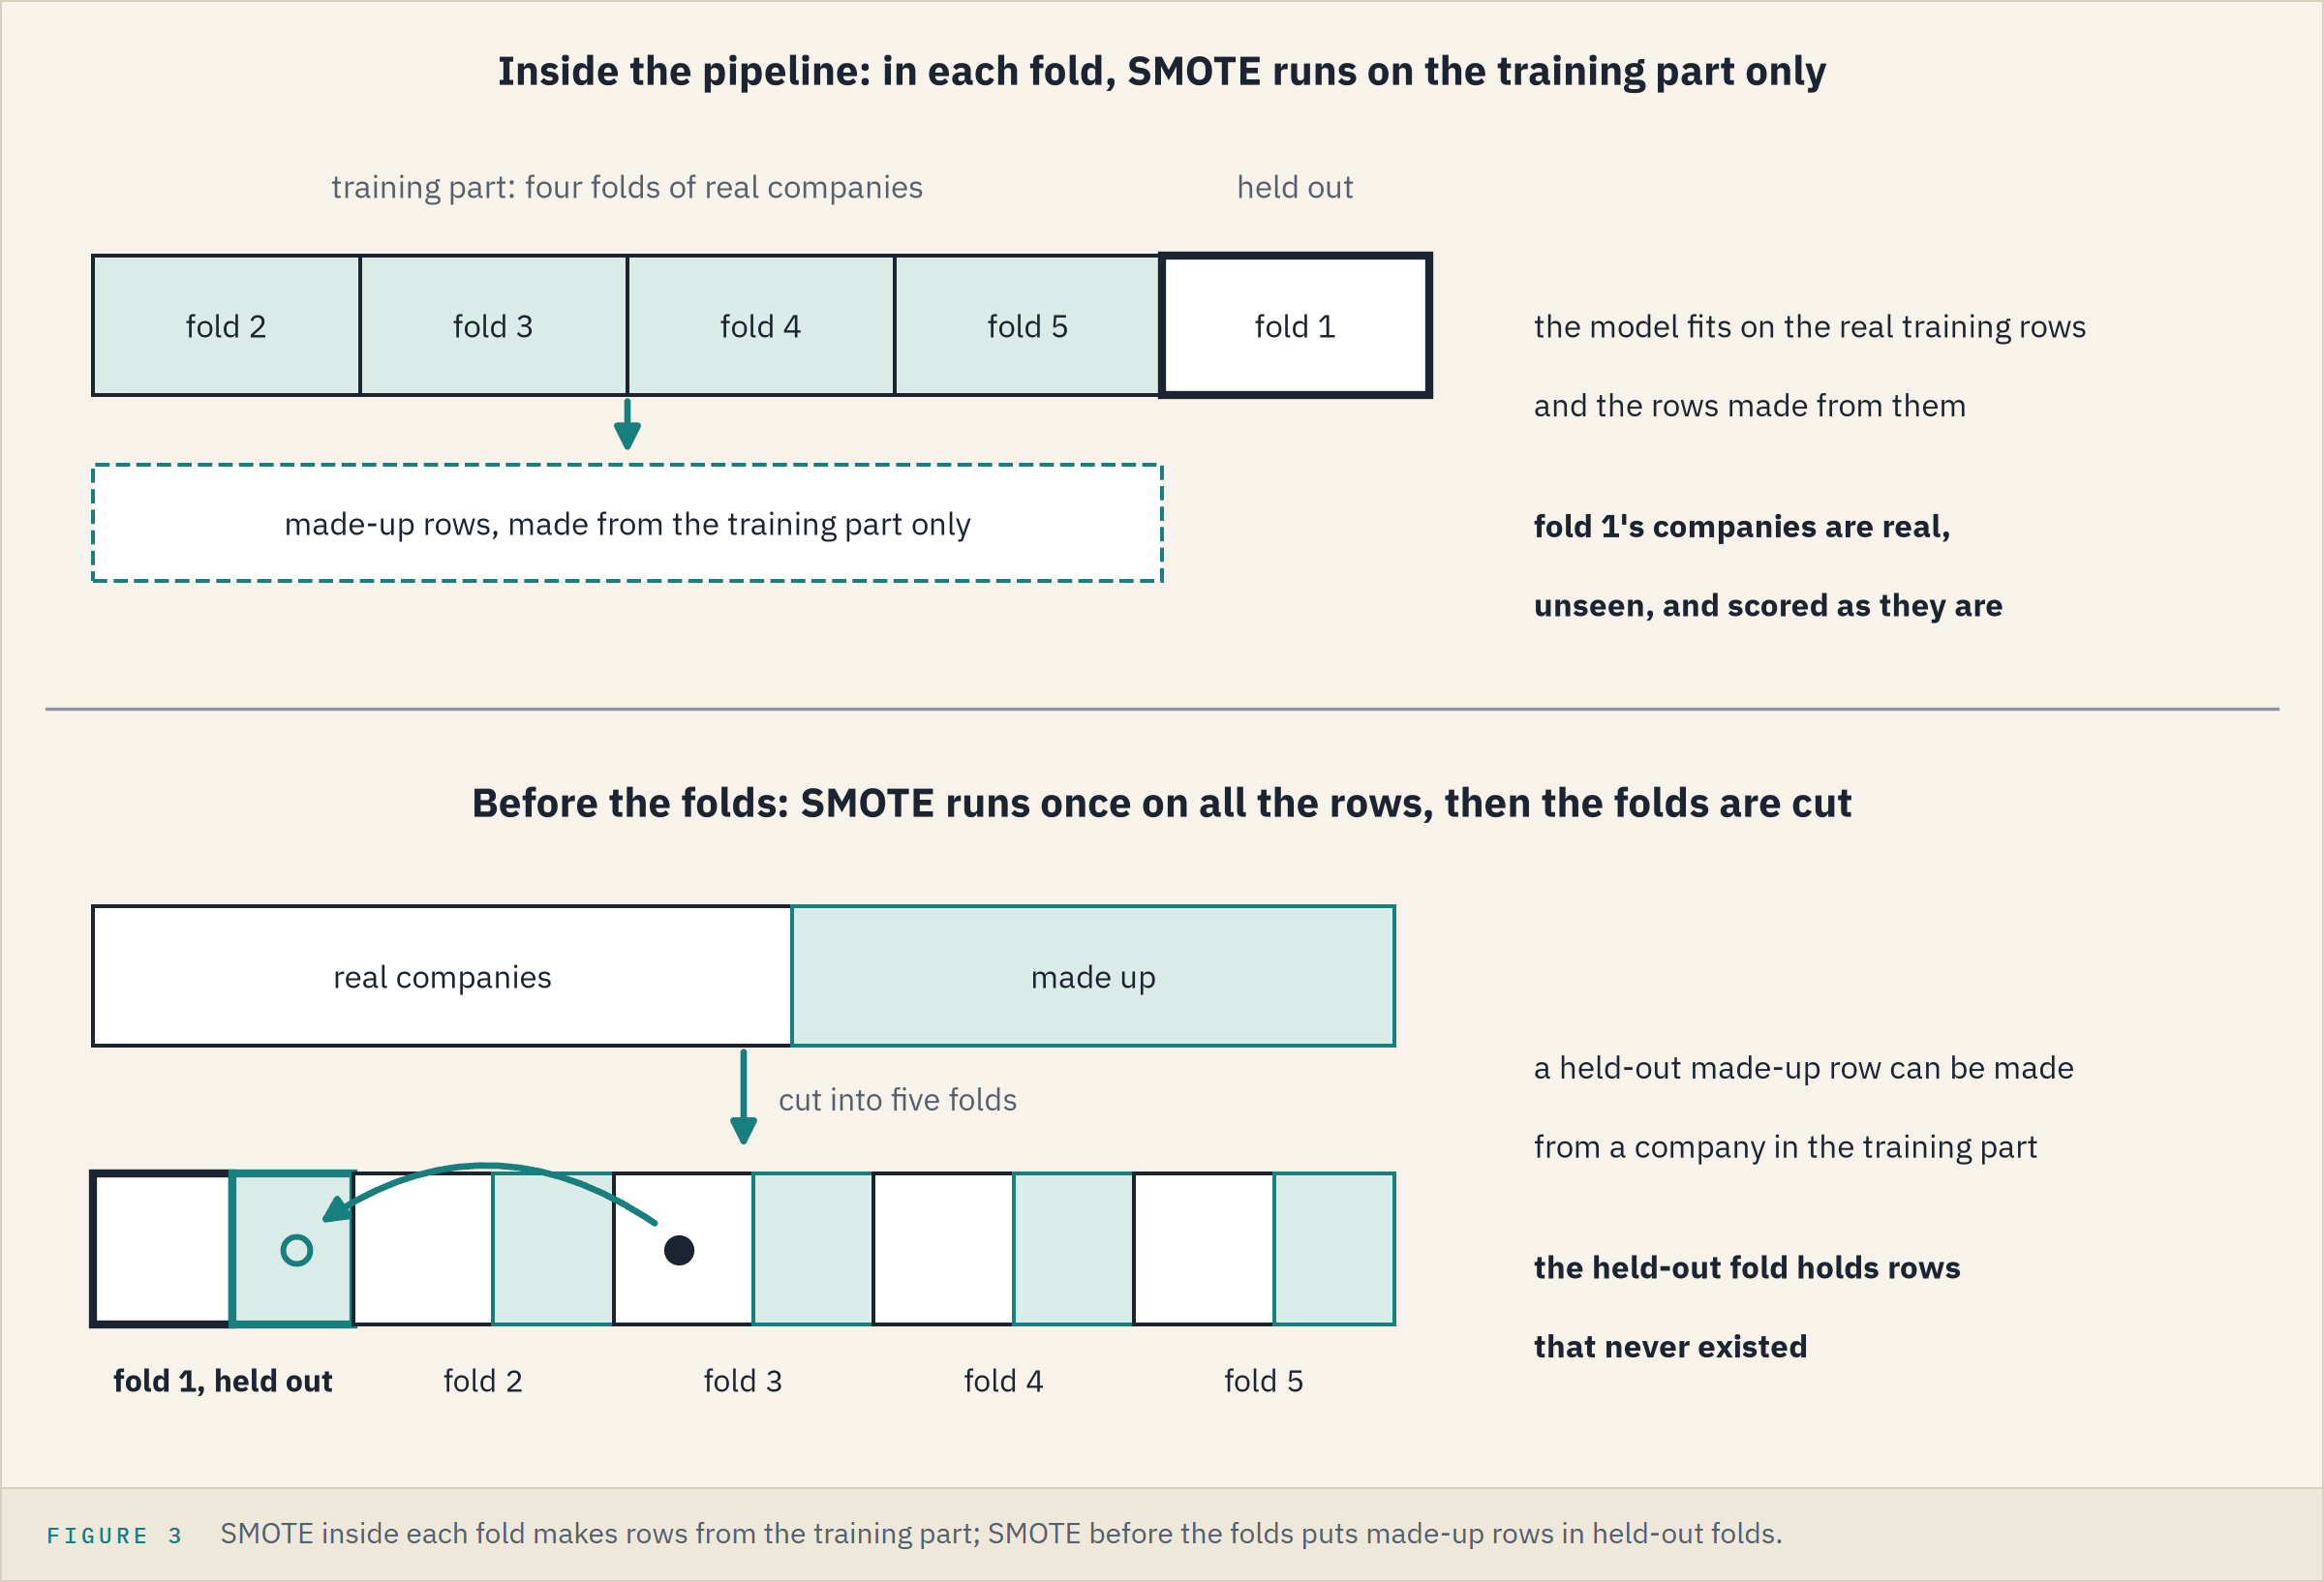

Inside the folds SMOTE costs the median-filled booster 0.13 of average precision.

**Predict 2**

SMOTE inside the folds scored 0.6239.

Q. Run SMOTE once on all 4,680 rows, then score the same booster on five folds of the result. Write down its fold average precision.

## The Mistake, Made on Purpose

In [25]:
# a demonstration of the mistake: fill and SMOTE all 4,680 rows first, then score the booster on five folds of the result
X_smote, y_smote = ImbPipeline([("impute", SimpleImputer(strategy="median")), ("smote", SMOTE(random_state=SEED))]).fit_resample(X_train, y_train)
leaked = cross_validate(booster, X_smote, y_smote, cv=folds, scoring=["average_precision", "roc_auc"], n_jobs=1)
print("Rows:", len(y_smote), " Folds:", leaked["test_average_precision"].round(4))
print("Mean:", round(leaked["test_average_precision"].mean(), 4), " ROC AUC:", round(leaked["test_roc_auc"].mean(), 4))

Rows: 8708  Folds: [0.9935 0.9954 0.9948 0.9981 0.9967]
Mean: 0.9957  ROC AUC: 0.9965


Nearly perfect on every fold, from a model that scores 0.6239 when SMOTE stays inside.

### Why the Score Jumped

In [26]:
# fold 1 of the 8,708 rows: its held-out bankrupt rows, and how many SMOTE made up (they come after row 4,680)
fit_rows, held_rows = next(folds.split(X_smote, y_smote))
made_up = np.arange(len(y_smote)) >= len(X_train)
held_bankrupt = held_rows[y_smote.to_numpy()[held_rows] == 1]
print("Held-out bankrupt rows:", len(held_bankrupt), " Made up:", made_up[held_bankrupt].sum(),
      " Share:", round(made_up[held_bankrupt].mean() * 100, 2), "percent")

Held-out bankrupt rows: 871  Made up: 807  Share: 92.65 percent


In [27]:
# a demonstration: the 64 filled ratios as normal scores, so no ratio's long tail decides who is near
scaled = QuantileTransformer(output_distribution="normal", random_state=SEED).fit_transform(X_smote)

# made-up held-out rows against their fold's training rows, and real held-out bankrupt companies in an honest fold 1
leak_gap = NearestNeighbors(n_neighbors=1).fit(scaled[fit_rows]).kneighbors(scaled[held_bankrupt[made_up[held_bankrupt]]])[0][:, 0]
honest_fit, honest_held = next(folds.split(X_train, y_train))
honest_gap = NearestNeighbors(n_neighbors=1).fit(scaled[honest_fit]).kneighbors(scaled[honest_held[went[honest_held]]])[0][:, 0]
print("Median distance to the nearest training row: made up", round(np.median(leak_gap), 2), " real", round(np.median(honest_gap), 2))

Median distance to the nearest training row: made up 0.8  real 3.91


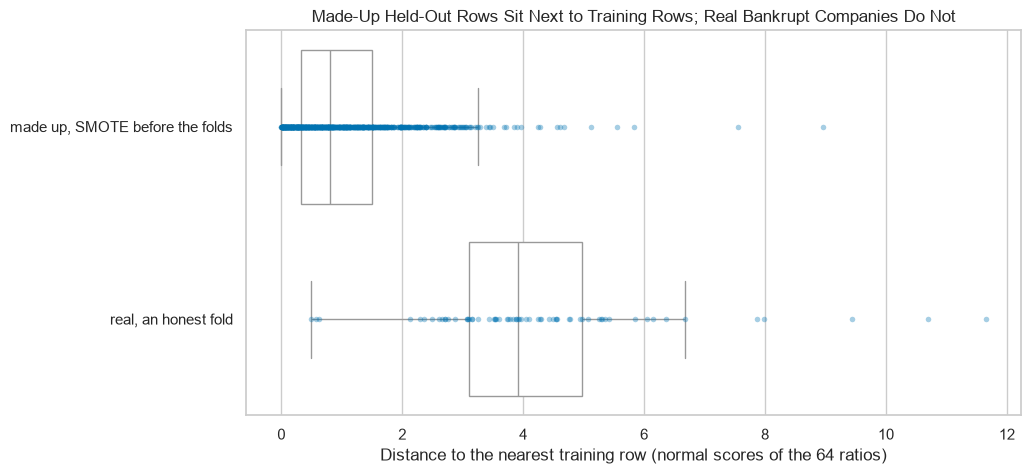

In [28]:
# the two sets of distances as horizontal box plots with every company drawn on top
gaps = pd.DataFrame({"distance": np.concatenate([leak_gap, honest_gap]),
                     "rows": ["made up, SMOTE before the folds"] * len(leak_gap) + ["real, an honest fold"] * len(honest_gap)})
sns.boxplot(data=gaps, x="distance", y="rows", color="white", showfliers=False)
sns.stripplot(data=gaps, x="distance", y="rows", jitter=False, size=4, alpha=0.35)
plt.xlabel("Distance to the nearest training row (normal scores of the 64 ratios)")
plt.ylabel("")
plt.title("Made-Up Held-Out Rows Sit Next to Training Rows; Real Bankrupt Companies Do Not")
plt.show()

807 of fold 1's 871 held-out bankrupt rows are made up, and the training part holds rows made from the same bankrupt companies.

A made-up row lies a median 0.8 from its nearest training row, a real bankrupt company 3.91.

The model is scored on near-copies of the rows it fitted: the same leak Course 4's Day 10 caught with copies.

**Resampling lives inside the pipeline, so each fold resamples its own training rows only; a score from rows resampled first measures memory, not ranking.**

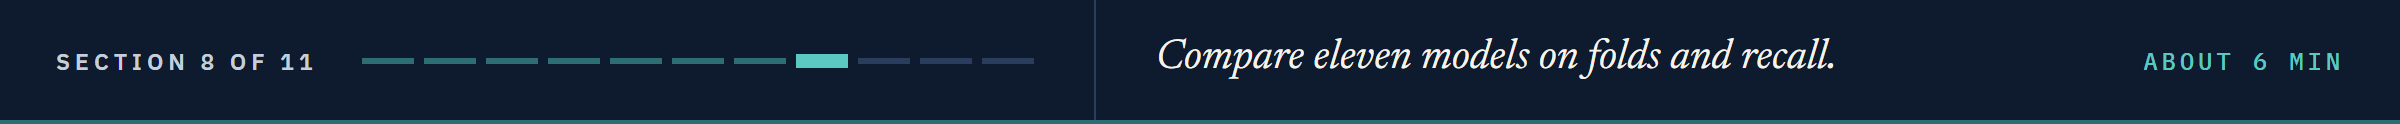

# Model Performance Comparison

## Eleven Models, One Set of Folds

In [29]:
# Course 4's two steps for the logistic regression, so a sampler can sit between them and the model
prep = [("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED))]
logit = LogisticRegression(solver="newton-cholesky", tol=1e-8)

# the fixes not yet fitted, each a pipeline the folds fit whole
more = {"LightGBM, copied": ImbPipeline([("copy", RandomOverSampler(random_state=SEED)), ("model", booster)]),
        "LightGBM, dropped": ImbPipeline([("drop", RandomUnderSampler(random_state=SEED)), ("model", booster)]),
        "logistic, copied": ImbPipeline(prep + [("copy", RandomOverSampler(random_state=SEED)), ("model", logit)]),
        "logistic, dropped": ImbPipeline(prep + [("drop", RandomUnderSampler(random_state=SEED)), ("model", logit)]),
        "logistic, SMOTE": ImbPipeline(prep + [("smote", SMOTE(random_state=SEED)), ("model", logit)])}

In [30]:
# every out-of-fold column in one table, LightGBM's family first
outputs = pd.DataFrame({"LightGBM": plain, "LightGBM, balanced": balanced, "LightGBM, median fill": filled,
                        "LightGBM, median fill, SMOTE": smote, "logistic": unweighted, "logistic, balanced (Course 4)": course4})
for name in more:
    outputs[name] = out_of_fold(more[name])
outputs = outputs[list(outputs.columns[:4]) + ["LightGBM, copied", "LightGBM, dropped"] + list(outputs.columns[4:6])
                  + ["logistic, copied", "logistic, dropped", "logistic, SMOTE"]]

# each column's five fold scores, their mean and their fold sd
board = pd.DataFrame({name: fold_ap(outputs[name]) for name in outputs}, index=range(1, 6)).T
board = board.assign(mean=board.mean(axis=1), sd=board.std(axis=1, ddof=0))
board

,1,2,3,4,5,mean,sd
LightGBM,0.7077,0.7988,0.7434,0.8013,0.8405,0.7783,0.0469
"LightGBM, balanced",0.6964,0.8101,0.7233,0.7895,0.8326,0.7704,0.0520
"LightGBM, median fill",0.7184,0.7628,0.7304,0.7684,0.8004,0.7561,0.0291
"LightGBM, median fill, SMOTE",0.5216,0.6625,0.5446,0.6935,0.6971,0.6239,0.0754
"LightGBM, copied",0.7036,0.8089,0.7461,0.7902,0.8177,0.7733,0.0427
"LightGBM, dropped",0.5640,0.6144,0.4853,0.6506,0.7641,0.6157,0.0926
logistic,0.5735,0.7511,0.6663,0.7107,0.7618,0.6926,0.0684
"logistic, balanced (Course 4)",0.5381,0.7195,0.6186,0.6750,0.7607,0.6624,0.0780
"logistic, copied",0.5341,0.7105,0.6111,0.6689,0.7229,0.6495,0.0697
"logistic, dropped",0.4919,0.6601,0.5619,0.6119,0.6992,0.6050,0.0729


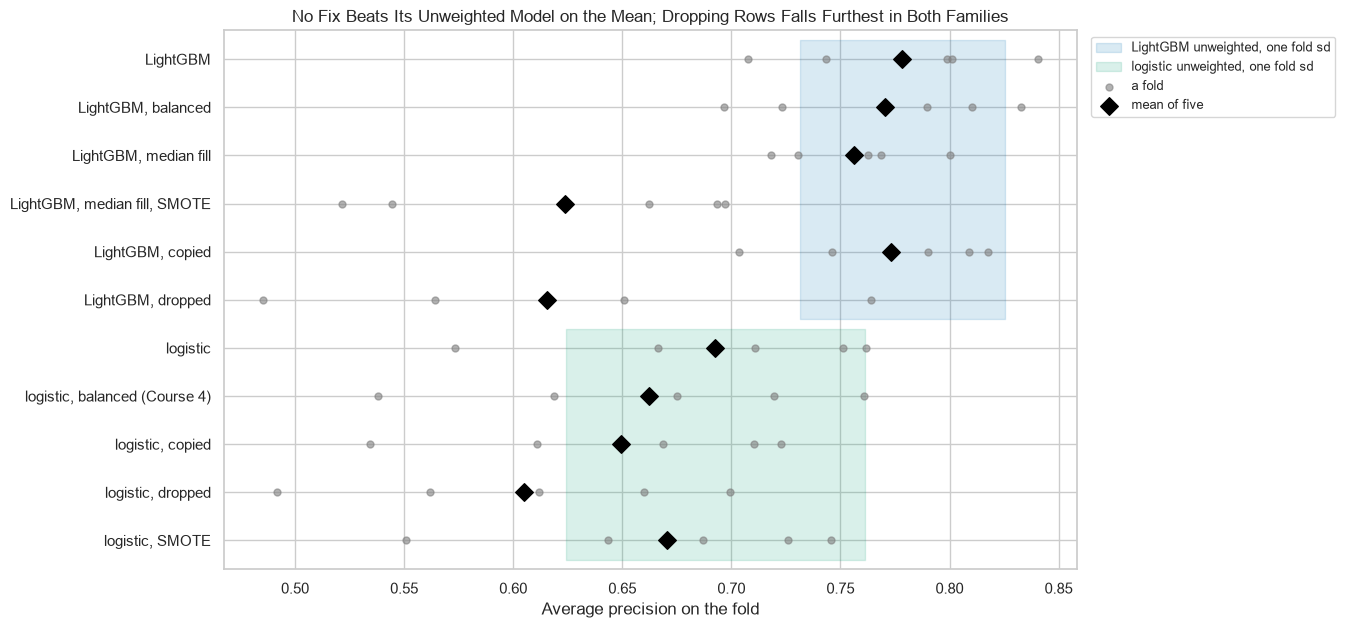

In [31]:
# five fold dots and the mean per model, each family's base model shaded at plus or minus one fold sd
# fill_betweenx is Course 2's fill_between turned on its side: it shades between two x values
fig, ax = plt.subplots(figsize=(11, 7))
for base, rows in [("LightGBM", (-0.4, 5.4)), ("logistic", (5.6, 10.4))]:
    mean, sd = board.loc[base, "mean"], board.loc[base, "sd"]
    ax.fill_betweenx(rows, mean - sd, mean + sd, color="C0" if base == "LightGBM" else "C2", alpha=0.15, label=base + " unweighted, one fold sd")
for k in range(1, 6):
    ax.scatter(board[k], range(len(board)), s=25, color="gray", alpha=0.6, label="a fold" if k == 1 else None)
ax.scatter(board["mean"], range(len(board)), marker="D", s=80, color="black", zorder=3, label="mean of five")
ax.set(yticks=range(len(board)), yticklabels=board.index, ylim=(10.6, -0.6), xlabel="Average precision on the fold")
ax.set_title("No Fix Beats Its Unweighted Model on the Mean; Dropping Rows Falls Furthest in Both Families")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.show()

No fix beats its own unweighted model.

Weights, copies and the logistic with SMOTE stay inside one fold sd of it; dropping rows, and SMOTE on the booster, fall outside.

Dropping costs LightGBM 0.16, and SMOTE costs the median-filled booster 0.13.

**Predict 3**

Day 11 read the threshold for a recall of 0.70 from out-of-fold outputs: the unweighted booster flags 327 companies to catch 229 of the 326.

Q. How many companies must the median-filled booster with SMOTE flag to catch the same 229? Write down a number.

## The Same Recall From a Threshold

Day 10's rule reads the highest threshold whose recall on the out-of-fold outputs is at least 0.70.

In [32]:
# Day 10's function: the highest threshold that keeps recall at 0.70 or more on these outputs
def threshold_for_recall(target, output, target_recall=0.70):
    precision, recall, thresholds = precision_recall_curve(target, output)
    return thresholds[recall[:-1] >= target_recall].max()

# each model at its own threshold: flagged, caught, and the share of flags that went bankrupt
at_70 = pd.DataFrame({"threshold": [threshold_for_recall(y_train, outputs[name]) for name in outputs]}, index=outputs.columns)
at_70["flagged"] = [(outputs[name] >= at_70.loc[name, "threshold"]).sum() for name in outputs]
at_70["caught"] = [((outputs[name] >= at_70.loc[name, "threshold"]) & went).sum() for name in outputs]
at_70["precision"] = at_70["caught"] / at_70["flagged"]
at_70

,threshold,flagged,caught,precision
LightGBM,0.0818,327,229,0.7003
"LightGBM, balanced",0.2208,333,229,0.6877
"LightGBM, median fill",0.0746,350,229,0.6543
"LightGBM, median fill, SMOTE",0.2692,518,229,0.4421
"LightGBM, copied",0.1715,347,229,0.6599
"LightGBM, dropped",0.9425,461,229,0.4967
logistic,0.1735,419,229,0.5465
"logistic, balanced (Course 4)",0.7134,481,229,0.4761
"logistic, copied",0.7228,473,229,0.4841
"logistic, dropped",0.8085,509,229,0.4499


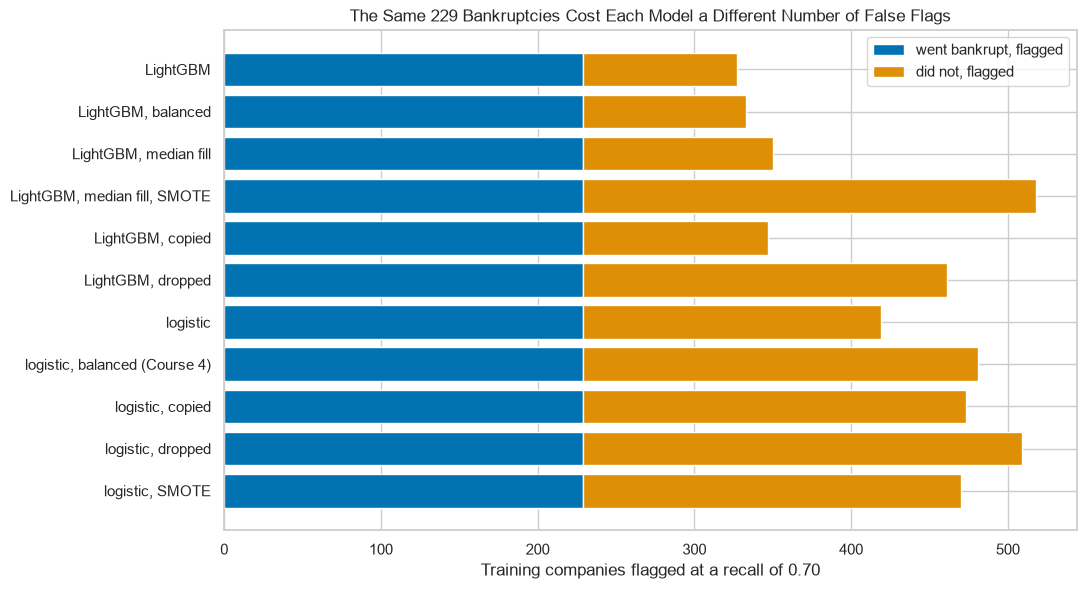

In [33]:
# caught and false flags at each model's threshold, stacked
plt.figure(figsize=(11, 6.5))
plt.barh(at_70.index, at_70["caught"], label="went bankrupt, flagged")
plt.barh(at_70.index, at_70["flagged"] - at_70["caught"], left=at_70["caught"], label="did not, flagged")
plt.gca().invert_yaxis()
plt.xlabel("Training companies flagged at a recall of 0.70")
plt.title("The Same 229 Bankruptcies Cost Each Model a Different Number of False Flags")
plt.legend(loc="upper right")
plt.show()

At a recall of 0.70 the unweighted booster flags the fewest companies of the eleven.

Every fix needs as many flags or more for the same catches.

## What a Lower Threshold Buys

Sort the companies by the unweighted booster's output, flag them from the top, and count the bankruptcies caught: the cumulative gains curve of Course 4's Day 10, in counts.

In [34]:
# the unweighted booster's companies from the highest output down: bankruptcies caught among the first n flagged
caught_curve = np.cumsum(went[np.argsort(-plain)])

# every model at 0.5: flagged, caught, and what the unweighted booster catches with as many flags
at_half = pd.DataFrame({"flagged": [(outputs[name] >= 0.5).sum() for name in outputs],
                        "caught": [((outputs[name] >= 0.5) & went).sum() for name in outputs]}, index=outputs.columns)
at_half["LightGBM, as many flags"] = caught_curve[at_half["flagged"] - 1]
at_half

,flagged,caught,"LightGBM, as many flags"
LightGBM,222,191,191
"LightGBM, balanced",258,201,206
"LightGBM, median fill",191,165,173
"LightGBM, median fill, SMOTE",361,197,236
"LightGBM, copied",261,206,207
"LightGBM, dropped",861,281,293
logistic,222,173,191
"logistic, balanced (Course 4)",712,268,278
"logistic, copied",714,265,278
"logistic, dropped",893,277,293


In [35]:
# the unweighted booster's curve, and every model's flags at 0.5 as a dot, one colour per family
def gains(ax):
    ax.plot(np.arange(1, len(plain) + 1), caught_curve, color="C0", linewidth=2.5, label="LightGBM, unweighted, any threshold")
    lightgbm = at_half.index.str.startswith("LightGBM")
    ax.scatter(at_half.loc[lightgbm, "flagged"], at_half.loc[lightgbm, "caught"], s=70, color="C1", zorder=3, label="LightGBM family at 0.5")
    ax.scatter(at_half.loc[~lightgbm, "flagged"], at_half.loc[~lightgbm, "caught"], s=70, color="C2", zorder=3, label="logistic family at 0.5")
    ax.axhline(326, color="gray", linestyle=":", label="all 326 bankruptcies")
    ax.set(xlim=(0, 1100), ylim=(0, 340), xlabel="Companies flagged", ylabel="Bankruptcies caught, of 326")
    ax.legend(loc="lower right")

### Your Turn: Slide the Threshold

Slide the unweighted booster's threshold and watch its marker move along its own curve.

In [36]:
# your turn: the unweighted booster at one threshold, marked on its curve
def draw_threshold(threshold=0.5):
    fig, ax = plt.subplots(figsize=(11, 6.5))
    gains(ax)
    flagged, caught = (plain >= threshold).sum(), ((plain >= threshold) & went).sum()
    ax.scatter(flagged, caught, s=250, marker="*", color="black", zorder=4)
    ax.set_title(f"Threshold {threshold:.2f}: {flagged} flagged, {caught} caught, precision {caught / flagged:.2f}")
    plt.show()

interact(draw_threshold, threshold=(0.02, 0.9, 0.02));

interactive(children=(FloatSlider(value=0.5, description='threshold', max=0.9, min=0.02, step=0.02), Output())…

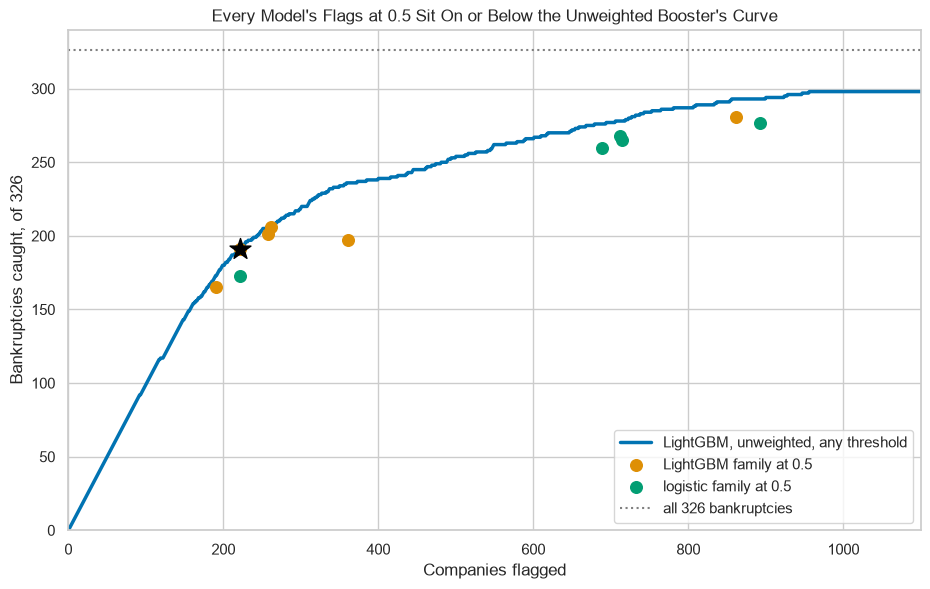

In [37]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
fig, ax = plt.subplots(figsize=(11, 6.5))
gains(ax)
ax.scatter((plain >= 0.5).sum(), ((plain >= 0.5) & went).sum(), s=250, marker="*", color="black", zorder=4)
ax.set_title("Every Model's Flags at 0.5 Sit On or Below the Unweighted Booster's Curve")
plt.show()

Balanced LightGBM flags 258 at 0.5 and catches 201; the unweighted booster catches 206 with as many flags.

The median-filled booster with SMOTE flags 361 and catches 197; the unweighted one catches 236 with 361.

**A lower threshold on the unweighted model reaches every recall the fixes reach at 0.5, with as few false flags or fewer.**

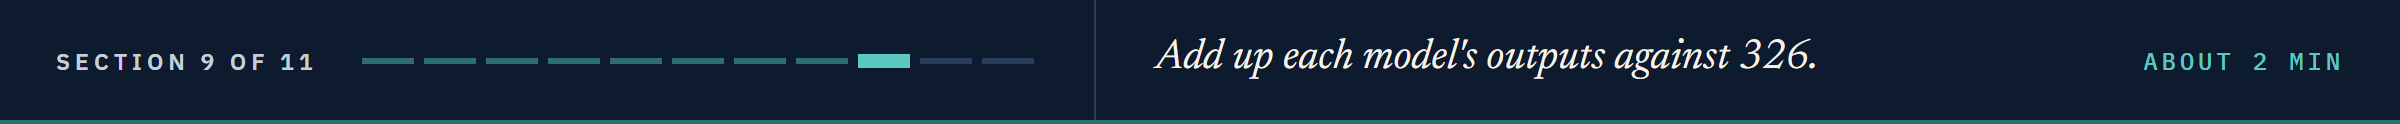

# What Each Fix Does to the Output

If each output is a company's probability of bankruptcy in this file, the outputs add up to the bankruptcies the model expects: about 326.

**Predict 4**

Q. Course 4's balanced logistic gives each of the 4,680 companies an output. What do they add up to? Write down a number.

## What the Scores Add Up To

The **Brier score** is the mean of (output - outcome) squared over the companies: it grows when outputs sit too high or too low, not only when the order is wrong.

In [38]:
# each model's mean output, its sum against 326 bankruptcies, and its Brier score
added = pd.DataFrame({"mean": outputs.mean(), "sum": outputs.sum(),
                      "Brier": [brier_score_loss(y_train, outputs[name]) for name in outputs]})
added

,mean,sum,Brier
LightGBM,0.0496,232.2847,0.0307
"LightGBM, balanced",0.0629,294.4497,0.0322
"LightGBM, median fill",0.0454,212.5469,0.0335
"LightGBM, median fill, SMOTE",0.0974,455.8510,0.0467
"LightGBM, copied",0.0624,292.0319,0.0314
"LightGBM, dropped",0.2010,940.5118,0.1061
logistic,0.0707,330.7802,0.0350
"logistic, balanced (Course 4)",0.2091,978.4179,0.0850
"logistic, copied",0.2087,976.8648,0.0857
"logistic, dropped",0.2374,1111.0226,0.1096


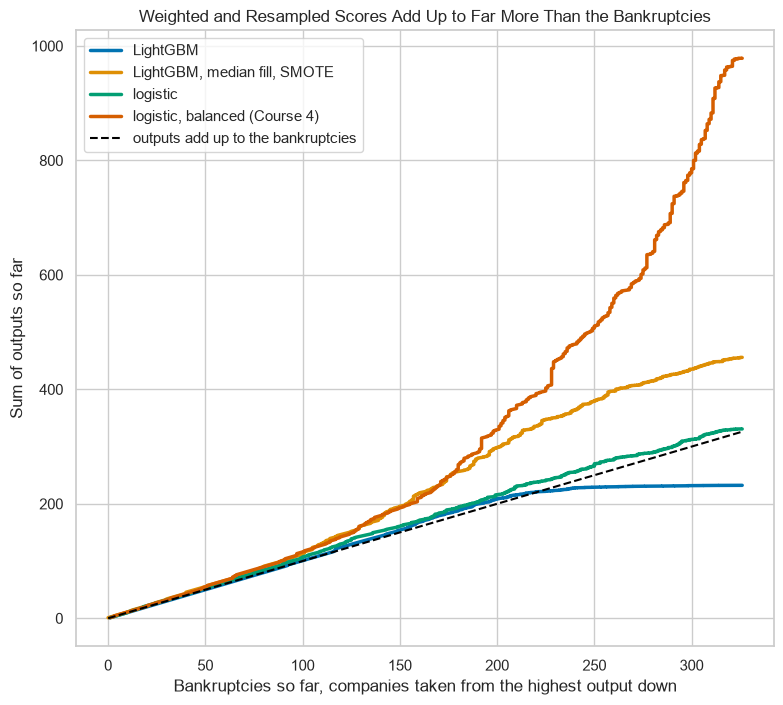

In [39]:
# companies from the highest output down: the running sum of outputs against the running count of bankruptcies
plt.figure(figsize=(9, 8))
for name in ["LightGBM", "LightGBM, median fill, SMOTE", "logistic", "logistic, balanced (Course 4)"]:
    order = np.argsort(-outputs[name].to_numpy())
    plt.plot(np.cumsum(went[order]), np.cumsum(outputs[name].to_numpy()[order]), linewidth=2.5, label=name)
plt.plot([0, 326], [0, 326], color="black", linestyle="--", label="outputs add up to the bankruptcies")
plt.xlabel("Bankruptcies so far, companies taken from the highest output down")
plt.ylabel("Sum of outputs so far")
plt.title("Weighted and Resampled Scores Add Up to Far More Than the Bankruptcies")
plt.legend(loc="upper left")
plt.show()

Course 4's logistic's scores add up to 978 where 326 companies went bankrupt: three times as many.

The unweighted logistic expects 331, and its Brier score is less than half of Course 4's.

The unweighted booster expects 232, too few: boosting's raw output needs care too.

**A weighted or resampled model's output is the model's score; before anyone reads it as a probability, it is recalibrated.**

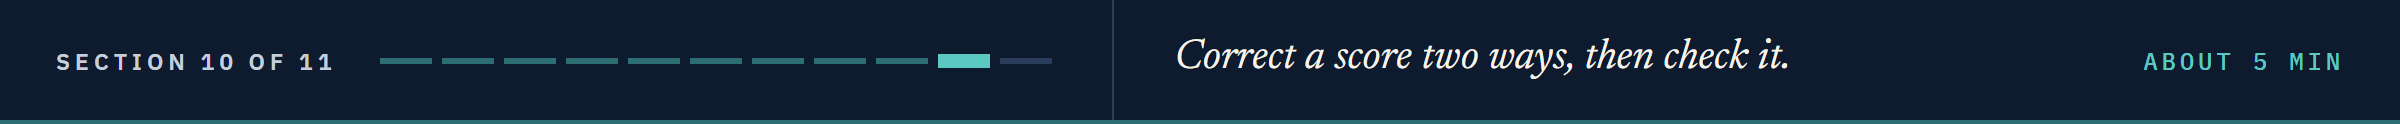

# Recalibration

The balanced weights fitted Course 4's logistic as if half the companies went bankrupt; in the file 6.97 percent did.
The **prior correction** turns its score back into a probability: multiply the score's odds by the file's odds, 0.0697 / 0.9303, over the fitted odds, 0.5 / 0.5.

**Predict 5**

Q. Sketch the corrected probability against the score, both from 0 to 1. Where does a score of 0.5 land?

## The Prior Correction

In [40]:
# the file's bankrupt share, and the correction: odds times the file's odds over the fitted odds, back to a probability
share = y_train.mean()
def prior_correction(score, fitted_share=0.5):
    odds = score / (1 - score) * (share / (1 - share)) / (fitted_share / (1 - fitted_share))
    return odds / (1 + odds)

corrected = prior_correction(course4)
print("Mean:", round(course4.mean(), 4), "to", round(corrected.mean(), 4), " Sum:", round(course4.sum(), 1), "to", round(corrected.sum(), 1))
print("Brier:", round(brier_score_loss(y_train, course4), 4), "to", round(brier_score_loss(y_train, corrected), 4),
      " Fold mean AP:", round(fold_ap(course4).mean(), 4), "to", round(fold_ap(corrected).mean(), 4))

Mean: 0.2091 to 0.074  Sum: 978.4 to 346.5
Brier: 0.085 to 0.0394  Fold mean AP: 0.6624 to 0.6624


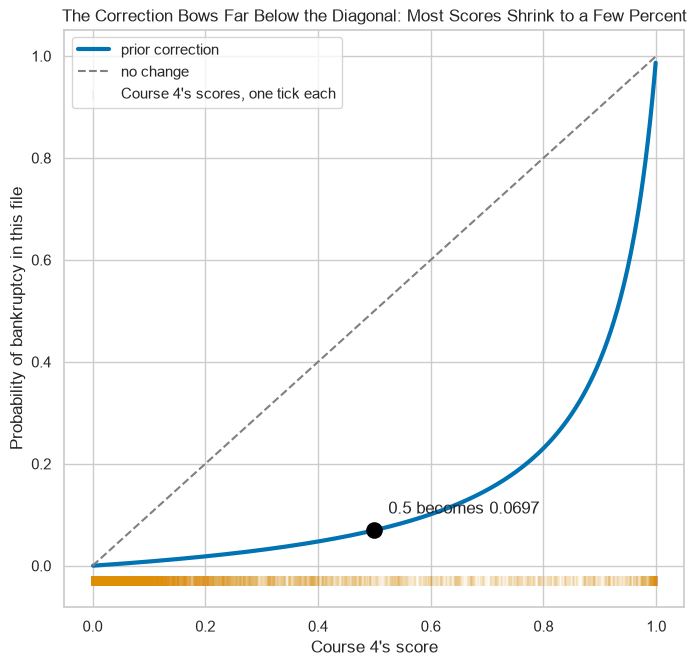

In [41]:
# the recalibration map: the correction's curve, the line where nothing changes, and a rug of Course 4's scores
scores = np.linspace(0.001, 0.999, 500)
plt.figure(figsize=(8, 7.5))
plt.plot(scores, prior_correction(scores), linewidth=3, label="prior correction")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="no change")
plt.scatter(course4, np.full(len(course4), -0.03), marker="|", s=60, color="C1", alpha=0.08, label="Course 4's scores, one tick each")
plt.scatter(0.5, prior_correction(0.5), s=120, color="black", zorder=3)
plt.annotate(f"0.5 becomes {prior_correction(0.5):.4f}", (0.5, prior_correction(0.5)), textcoords="offset points", xytext=(10, 12))
plt.xlabel("Course 4's score")
plt.ylabel("Probability of bankruptcy in this file")
plt.title("The Correction Bows Far Below the Diagonal: Most Scores Shrink to a Few Percent")
plt.legend(loc="upper left")
plt.show()

The mean falls from 0.2091 to 0.074, near the file's 0.0697, and the sum from 978 to 347.

The Brier score more than halves, and average precision does not move: the correction keeps the order.

### Where the Formula Fails

In [42]:
# the same correction on the balanced booster's scores
print("Mean:", round(balanced.mean(), 4), "to", round(prior_correction(balanced).mean(), 4),
      " Sum:", round(prior_correction(balanced).sum(), 1), "against 326")

Mean: 0.0629 to 0.0403  Sum: 188.5 against 326


The formula assumes the score was a probability for the weighted rows, as a logistic's is.

The balanced booster's score was not one, and its correction falls well short of 326.

## Isotonic Calibration, Learned Inside the Folds

**Isotonic calibration** fits a staircase that only rises, from a model's output to the share that went bankrupt, on outputs from rows the model did not fit.
`CalibratedClassifierCV(method="isotonic")` does both inside the rows it is given: on folds of its own, it fits the model on two parts and the staircase on the third, three times, and averages the three.
Inside `out_of_fold`, all of that happens within each training part, and the held-out fold only receives outputs.

In [43]:
# a model with an isotonic staircase learned on three seeded folds of its own
def isotonic(model):
    return CalibratedClassifierCV(model, method="isotonic", cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), n_jobs=1)

# the unweighted booster and Course 4's logistic, each recalibrated
recalibrated = pd.DataFrame({"LightGBM, isotonic": out_of_fold(isotonic(booster)),
                             "logistic, balanced (Course 4), isotonic": out_of_fold(isotonic(logistic("balanced")))})
pd.DataFrame({"mean": recalibrated.mean(), "sum": recalibrated.sum(),
              "Brier": [brier_score_loss(y_train, recalibrated[name]) for name in recalibrated],
              "fold mean AP": [fold_ap(recalibrated[name]).mean() for name in recalibrated],
              "flagged at 0.70": [(recalibrated[name] >= threshold_for_recall(y_train, recalibrated[name])).sum() for name in recalibrated]})

,mean,sum,Brier,fold mean AP,flagged at 0.70
"LightGBM, isotonic",0.0701,328.2826,0.0296,0.7708,357
"logistic, balanced (Course 4), isotonic",0.0698,326.5709,0.0365,0.6789,471


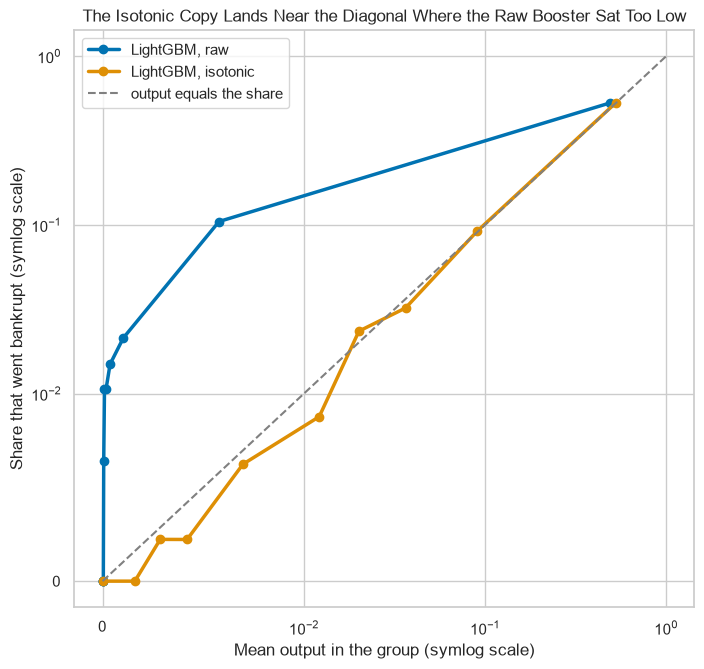

In [44]:
# the reliability diagram of Course 4's Day 8: ten groups of companies by output, the share that went bankrupt in each
plt.figure(figsize=(8, 7.5))
for name, output in [("LightGBM, raw", plain), ("LightGBM, isotonic", recalibrated["LightGBM, isotonic"])]:
    bankrupt_share, mean_output = calibration_curve(y_train, output, n_bins=10, strategy="quantile")
    plt.plot(mean_output, bankrupt_share, marker="o", linewidth=2.5, label=name)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="output equals the share")
plt.xscale("symlog", linthresh=0.01)
plt.yscale("symlog", linthresh=0.01)
plt.xlabel("Mean output in the group (symlog scale)")
plt.ylabel("Share that went bankrupt (symlog scale)")
plt.title("The Isotonic Copy Lands Near the Diagonal Where the Raw Booster Sat Too Low")
plt.legend(loc="upper left")
plt.show()

The isotonic booster's outputs add up to 328 where 326 went bankrupt, and its Brier score falls.

It costs the booster a little ranking, inside one fold sd: its staircase ties companies that the raw booster told apart.

On Course 4's logistic it gives ranking back, 0.6789 against 0.6624, and its outputs add up to 327.

**The unweighted LightGBM ranks; its isotonic copy reports a probability whose sum matches the rows.**

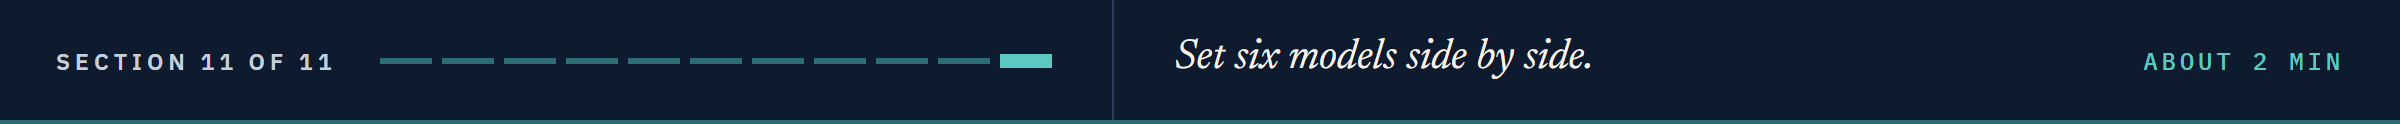

# Insights and Conclusion

In [45]:
# six models on four measures, further out is worse: three scaled so the unweighted booster is 1
# the sum's axis is how many times too high or too low the sum is against 326, so 1 means it matches
measures = pd.DataFrame({"fold mean AP": board["mean"], "flags at recall 0.70": at_70["flagged"],
                         "sum, times off 326": np.maximum(added["sum"] / 326, 326 / added["sum"]), "Brier": added["Brier"]})
six = ["LightGBM", "LightGBM, balanced", "LightGBM, median fill, SMOTE", "logistic", "logistic, balanced (Course 4)", "logistic, SMOTE"]
radar = measures.loc[six] / measures.loc["LightGBM"]
radar["fold mean AP"] = measures.loc["LightGBM", "fold mean AP"] / measures.loc[six, "fold mean AP"]
radar["sum, times off 326"] = measures.loc[six, "sum, times off 326"]
radar

,fold mean AP,flags at recall 0.70,"sum, times off 326",Brier
LightGBM,1.0000,1.0000,1.4035,1.0000
"LightGBM, balanced",1.0103,1.0183,1.1072,1.0497
"LightGBM, median fill, SMOTE",1.2476,1.5841,1.3983,1.5218
logistic,1.1237,1.2813,1.0147,1.1411
"logistic, balanced (Course 4)",1.1750,1.4709,3.0013,2.7682
"logistic, SMOTE",1.1607,1.4373,2.7945,2.6495


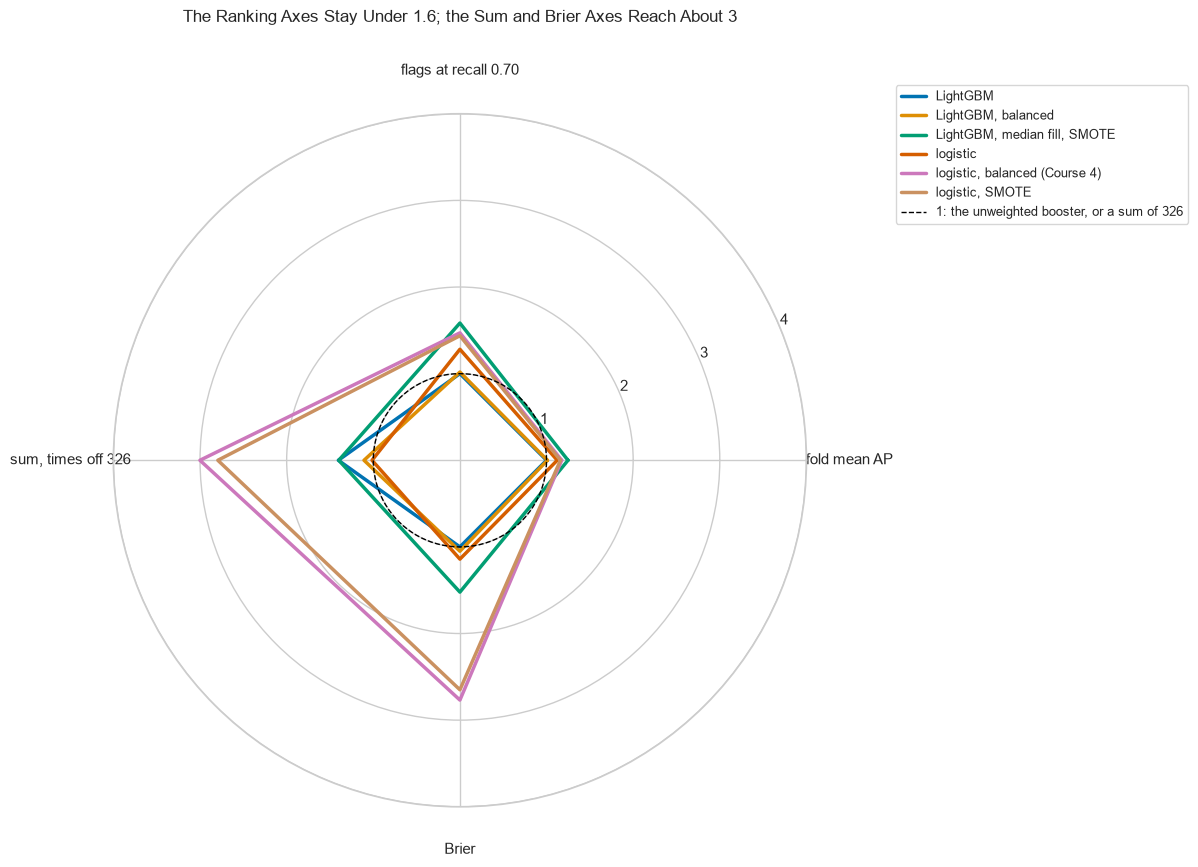

In [46]:
# a radar: one axis per measure, one closed line per model, the ring at 1 dashed
angles = np.linspace(0, 2 * np.pi, 4, endpoint=False).tolist() + [0]
fig, ax = plt.subplots(figsize=(11, 9), subplot_kw={"projection": "polar"})
for name in six:
    ax.plot(angles, radar.loc[name].tolist() + [radar.loc[name].iloc[0]], linewidth=2.5, label=name)
ax.plot(np.linspace(0, 2 * np.pi, 100), np.ones(100), color="black", linestyle="--", linewidth=1, label="1: the unweighted booster, or a sum of 326")
ax.set_xticks(angles[:-1], radar.columns)
ax.set_yticks([1, 2, 3, 4])
ax.tick_params(axis="x", pad=18)
ax.set_title("The Ranking Axes Stay Under 1.6; the Sum and Brier Axes Reach About 3", pad=30)
ax.legend(loc="upper left", bbox_to_anchor=(1.12, 1.05), fontsize=9)
plt.show()

On this file no weight or resample ranked better than the same model unweighted, and Course 4's weights cost its logistic 0.03 of average precision.

The recall a fix buys at 0.5, a lower threshold on the unweighted model buys with as few flags or fewer.

SMOTE run before the folds scored near-perfect on held-out rows it had made itself: memory, not ranking.

A weighted logistic's scores added up to three times the bankruptcies; the prior correction fixes a weighted logistic, and isotonic calibration fixed both models here, at a small cost in ranking for the booster.

These are findings about this file and these models, not a law: on another file a fix may help, and the folds are how to find out.

**Day 14 opens the unweighted LightGBM and splits its log-odds across the 64 ratios.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Weight the rare class with `class_weight="balanced"` and say what the weights are.
* Copy, drop and synthesize rows with imbalanced-learn's samplers inside an `ImbPipeline`.
* Build one SMOTE row by hand from a company and a neighbour.
* Compare models on the same folds and at one recall, from out-of-fold outputs.
* Measure what a fix does to a model's output with its sum and the Brier score.
* Recalibrate a score with the prior correction and with isotonic calibration.

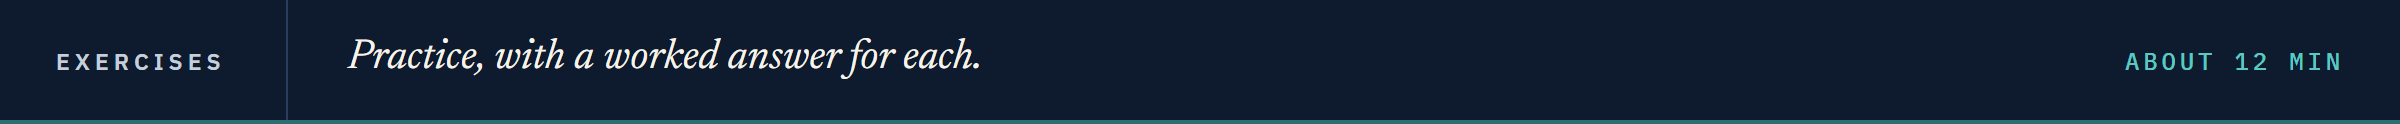

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [47]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Three Neighbours**

Q. Put `SMOTE(k_neighbors=3, random_state=SEED)` in place of `SMOTE(random_state=SEED)` in the median-filled booster's pipeline. Store its fold mean average precision in `ex1_ap`.

In [48]:
# your code here
ex1_ap = ...

In [49]:
check("Exercise 1 SMOTE with three neighbours", ex1_ap, 0.6052473001182124)

Exercise 1 SMOTE with three neighbours: not attempted yet


### Exercise 2

**Dropping Rows for a Forest**

Q. Build a pipeline of the median imputer and Day 3's `RandomForestClassifier(n_estimators=100, min_samples_leaf=3, random_state=SEED, n_jobs=1)`, and an `ImbPipeline` with `RandomUnderSampler(random_state=SEED)` between them. Store each one's fold mean average precision in `ex2_plain` and `ex2_dropped`, and the undersampled forest's mean output in `ex2_mean`.

In [50]:
# your code here
ex2_plain = ...
ex2_dropped = ...
ex2_mean = ...

In [51]:
check("Exercise 2 the forest", ex2_plain, 0.486629715170651)
check("Exercise 2 the forest on dropped rows", ex2_dropped, 0.4118819682855501)
check("Exercise 2 its mean output", ex2_mean, 0.3366342664458049)

Exercise 2 the forest: not attempted yet
Exercise 2 the forest on dropped rows: not attempted yet
Exercise 2 its mean output: not attempted yet


### Exercise 3

**Correcting the SMOTE Logistic**

Q. SMOTE fitted the logistic on balanced rows. Apply `prior_correction` to the `"logistic, SMOTE"` column of `outputs`. Store the corrected outputs' sum in `ex3_sum`, and the companies flagged at the corrected outputs' threshold for a recall of 0.70 in `ex3_flagged`.

In [52]:
# your code here
ex3_sum = ...
ex3_flagged = ...

In [53]:
check("Exercise 3 the corrected sum", ex3_sum, 347.10391953732017)
check("Exercise 3 flagged at a recall of 0.70", ex3_flagged, 470)

Exercise 3 the corrected sum: not attempted yet
Exercise 3 flagged at a recall of 0.70: not attempted yet


### Exercise 4: AI check

**The Balanced Rows That Scored Too Well**

You asked an AI assistant for out-of-fold outputs of the booster with SMOTE, to choose a threshold.
This came back.
It runs, and its average precision is far above anything today.
Test it, then find the one bug.

In [54]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
# balance the classes with SMOTE (gaps filled first), then take each row's out-of-fold output
X_balanced, y_balanced = ImbPipeline([("impute", SimpleImputer(strategy="median")), ("smote", SMOTE(random_state=SEED))]).fit_resample(X_train, y_train)
ai_output = cross_val_predict(booster, X_balanced, y_balanced, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
print("Average precision:", round(average_precision_score(y_balanced, ai_output), 4))

Average precision: 0.9957


In [55]:
# the test: one out-of-fold output for each of the 4,680 training companies, and no others
assert len(ai_output) == len(X_train), f"{len(ai_output):,} outputs for {len(X_train):,} companies: rows were made before the folds"

AssertionError: 8,708 outputs for 4,680 companies: rows were made before the folds

Q. Fix it, so SMOTE runs inside each fold's training part, and store the average precision of the fixed outputs over the 4,680 companies in `ex4_ap`.

In [56]:
# your code here
ex4_ap = ...

In [57]:
check("Exercise 4 SMOTE inside the folds", ex4_ap, 0.6124363144299683)

Exercise 4 SMOTE inside the folds: not attempted yet


## Congratulations!

You took the advice every tutorial gives for a rare class and tested it on the folds.
You weighted, copied, dropped and made up rows, built a synthetic company by hand, and caught SMOTE scoring near-perfect on rows it had made itself.
You found that a lower threshold buys the same catches, and that a weighted output is a score until it is recalibrated.
That habit, asking what a fix does to the ranking and to the output separately, is what a model review needs.
In Day 14 you open the unweighted booster and read what it leans on, company by company.

[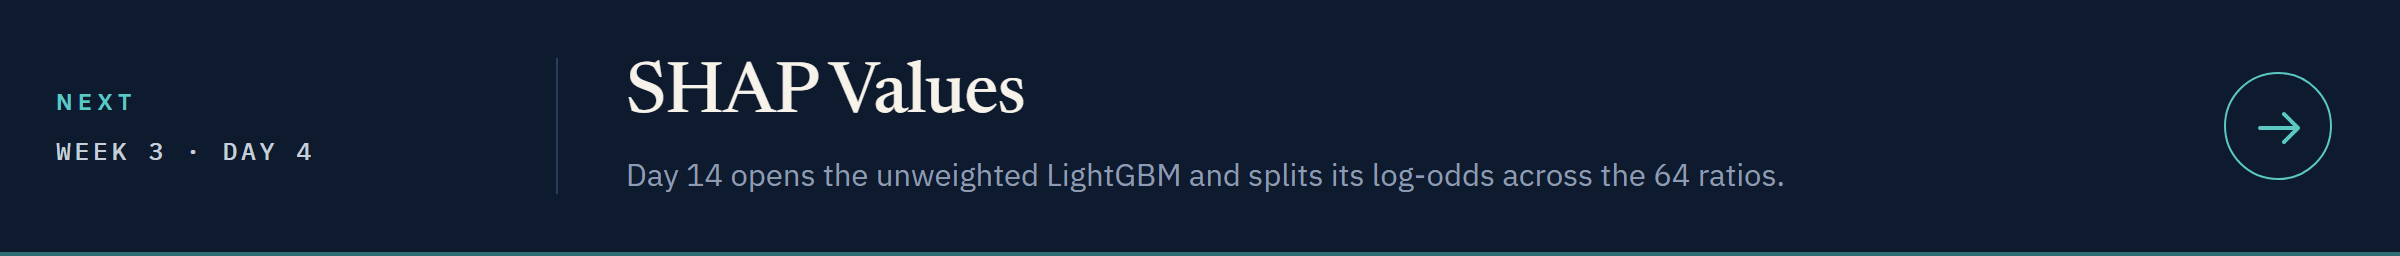](../day4/14_shap_values.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day4/14_shap_values.ipynb)